In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statistics as st
import pickle

import warnings

from tqdm.notebook import tqdm
from scipy.stats import beta
from scipy import stats
from scipy import integrate
from scipy import special
from matplotlib.backends.backend_pdf import PdfPages

In [2]:
#Simulation_itelation

rep_sim = 1000
rep_sim = 100000
rep_sim = 445*10**3

In [3]:
# Difinition of Runge-Kutta methods

def rk4 ( y, t, h, f ):
    k1 = h * f( y, t )
    k2 = h * f( y + k1/2, t + h/2 )
    k3 = h * f( y + k2/2, t + h/2 )
    k4 = h * f( y + k3, t + h )
    return  y + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h

In [4]:
# Seed definitions

def SEEDS(seed):
    seeds = seed
    if seeds > 2**32 - 1:
        seeds = seeds/0.9 - 2**32
        if seeds > 2**32 - 1:
            seeds = seeds/0.9 - 2**32
            if seeds > 2**32 - 1:
                seeds = seeds/0.9 - 2**32
    np.random.seed(round(seeds))
    DecidedSeed = np.random.randint(0, 2**32)
    return DecidedSeed

In [5]:
# Difinition of PERT distribution

def PERT(a,b,c):
    return a+(c-a)*np.random.beta(1+4*(b-a)/(c-a), 1+4*(c-b)/(c-a))

In [6]:
# Difinition of dynamic tempareture MCMC simulation using the Metropolis-Hastings algorithm (Normal dist.)
#メトロポリスヘイスティング (正規分布)
def Metropolis_Hastings_norm(Temp_mean, sigma_Temp, Time_end, Temp0):
    Time_end = round(Time_end,1)
    def f(x):
        return stats.norm.pdf(x, Temp_mean, sigma_Temp)

    burn_in = 0
    xs = np.linspace(0, Time_end, int(Time_end*10+1), endpoint = True)
    res = np.zeros(len(xs)+burn_in)
    y = Temp0
    for i in range(burn_in+res.shape[0]):
        y_candidate = y + 0.5*stats.norm.rvs()
        r = f(y_candidate) / f(y)
        u = np.random.rand()
        if i >= burn_in:
            res[i-burn_in] = y
            if u < r:
                y = y_candidate
            else:
                y = res[i-burn_in]
    return xs, res[burn_in:]

In [7]:
# Difinition of dynamic tempareture MCMC simulation using the Metropolis-Hastings algorithm (PERT dist.)
#メトロポリスヘイスティング　（PERT分布）
def Metropolis_Hastings_pert(Temp_min, Temp_med, Temp_max, Time_end, Temp0):
    Time_end = round(Time_end,1)
    alpha = 1+4*(Temp_med-Temp_min)/(Temp_max-Temp_min)
    beta = 1+4*(Temp_max-Temp_med)/(Temp_max-Temp_min)

    def f(x):
        x_pert = (x - Temp_min)/(Temp_max-Temp_min)
        return stats.beta.pdf(x_pert, alpha, beta)

    burn_in = 0
    xs = np.linspace(0, Time_end, int(Time_end*10+1), endpoint = True)
    res = np.zeros(len(xs)+burn_in)
    
    if Temp0 > Temp_max:
        Temp0pert = Temp_max
    if Temp0 < Temp_min:
        Temp0pert = Temp_min
    else:
        Temp0pert = Temp0
    
    y = Temp0pert
    for i in range(burn_in+res.shape[0]):
        y_candidate = y + 0.5*stats.norm.rvs()
        r = f(y_candidate) / f(y)
        u = np.random.rand()
        if i >= burn_in:
            res[i-burn_in] = y
            if u < r:
                y = y_candidate
            else:
                y = res[i-burn_in]
    return xs, res[burn_in:]

In [8]:
def Mass_lettuce():  # This study
    return PERT(300, 480, 650)

In [9]:
def Prev_Init_Letuce(m_lettuce):
    # Prevalence (Wjinand, 2014)
    Pre_P = np.random.beta(3+1,1810-3+1)
    CheckLettuceContami = np.random.binomial(n = 1, p = Pre_P)
    
    # Initial Count (logCFU/g) (Wjinand, 2014)
    logC_initial = np.random.normal(0.10, 0.21)
    
    if CheckLettuceContami == 0:
        logC_initial = -float('inf')
    
    return Pre_P, CheckLettuceContami, logC_initial # (-), logcfu/g

In [10]:
def Prev_Init_Meat():
    ID_choice = 0
    if ID_choice == 0:
        # Prevalence (Food Safety Commission of Japan, 2016)
        Pre_P = PERT(0.32, 0.658, 0.96)
        CheckMeatContami = np.random.binomial(n = 1, p = Pre_P)

        # Initial Count (log CFU/g) (Ono, 2004; log CFU/100g)
        
        X = [np.log10(5.5)-1.5-2, np.log10(5.5)+0.5-2, np.log10(5.5)+1.5-2, np.log10(5.5)+2.5-2, np.log10(5.5)+3.5-2, np.log10(5.5)+5.5-2]
        P = [0, 25, 47.7, 76.6, 96.9, 100]

        p = np.random.uniform(np.min(P), np.max(P))

        for i in range(len(P)):
            if not i==np.max(range(len(P))):
                if ((P[i]<= p)&(p<P[i+1])):
                    logC_initial = np.random.uniform(X[i], X[i+1])
        if CheckMeatContami == 0:
            logC_initial = -float('inf')
    
    return Pre_P, CheckMeatContami, logC_initial # (-), logcfu/g

In [11]:
def rk4_Baranyi_dqdt(q, t, h, mu_max):
    def f (q, t):
        return mu_max * q
    k1 = h * f( q, t )
    k2 = h * f( q + k1/2, t + h/2 )
    k3 = h * f( q + k2/2, t + h/2 )
    k4 = h * f( q + k3, t + h )
    return  q + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h
        
def rk4_Baranyi_Baranyi_dCdt(C, t, h, mu_max, q, Cmax):
    def f (C, t):
        return mu_max * q / (1+q) * (1 - C/Cmax) * C
    k1 = h * f( C, t )
    k2 = h * f( C + k1/2, t + h/2 )
    k3 = h * f( C + k2/2, t + h/2 )
    k4 = h * f( C + k3, t + h )
    return  C + ( k1 + 2*k2 + 2*k3 + k4 )/6,t+h
        
    
def Differential_Baranyi_dqdt(q, mu_max):  ### q description
    return mu_max * q
    
def Differential_Baranyi_dCdt(C, mu_max, q, Cmax):  ### Natural log
    return mu_max * q / (1+q) * (1 - C/Cmax) * C


In [12]:
def Cross_probs():
    X_meat2uten  = np.random.beta(0.33+1, 0.53) # ??? Dharod et al., 2009???
    X_meat2hand  = np.min([np.random.lognormal(0.94, 0.68)/100, 1])
    X_uten2hand  = np.random.beta(0.33+1, 0.53)
    CheckHandWash = np.random.binomial(1, 0.5)
    if CheckHandWash == 1:
        x_remain_wash  = np.min([np.random.lognormal(-0.20, 1.42)/100, 1])
    if CheckHandWash == 0:
        x_remain_wash  = 1
    X_hand2lettuce = np.min([np.random.lognormal(-0.80, 1.09)/100, 1])
    
    return X_meat2uten, X_meat2hand, X_uten2hand, x_remain_wash, X_hand2lettuce, CheckHandWash

In [13]:
def DRmodel_Appro_Beta_Pois(Dose):
    alpha_BetaPois = 0.057 #Teunis et al., 2005
    beta_BetaPois = 0.047 #Teunis et al., 2005
    P_DR = 1.0 - (1+Dose/beta_BetaPois)**-alpha_BetaPois #Approximate Beta-Poisson DR model
    return P_DR

In [14]:
def ServeSize(m_lettuce):
    servesize = m_lettuce/round(m_lettuce/85) # 85g of mean size FDA???
    return servesize # g

In [15]:
def PackSize_Meat():
    return PERT(150, 200, 250) # g  # 85g of mean size FDA??? # This study (200 gくらいでパック売りしているイメージ)
def ServeSize_Meat():
    return PERT(50, 85, 250) # g  # 85g of mean size FDA??? # This study (200 gくらいでパック売りしているイメージ)

In [16]:
def determineInfection(P_inf):
    return np.random.binomial(1, P_inf)

In [4]:
def QMRA_calculations(ID_sim):
    ### Setting of the seed for the random numbers
    np.random.seed(SEEDS(19990128+ID_sim))
    
    ### Weight of lettuce
    m_lettuce = Mass_lettuce()
    m_meat = PackSize_Meat()
    
    ### Prevalence and Initial conc.
    p_lettuce, checklettuce0, logC0_lettuce = Prev_Init_Letuce(m_lettuce) # Lettuce
    p_meat, checkmeat0, logC0_meat  = Prev_Init_Meat() # meat
    
    ### Initial count in lettuce
    N0 = m_lettuce * 10**logC0_lettuce # CFU
    N0 = np.random.poisson(N0) # CFU
    logN0 = np.log10(N0) # logCFU
    logC0_lettuce = np.log10(N0/m_lettuce) # logCFU/g
    
    ### Initial count in meat
    N0_meat = m_meat * 10**logC0_meat # CFU
    N0_meat = np.random.poisson(N0_meat) # CFU
    logN0_meat = np.log10(N0_meat) # logCFU
    logC0_meat = np.log10(N0_meat/m_meat) # logCFU/g
    
    
    ### No growth during storage
    N_home_lettuce = N_trans_lettuce = N0
    logC_home_lettuce = logC_trans_lettuce = logC0_lettuce
    
    N_home_meat = N_trans_meat = N0_meat
    logC_home_meat = logC_trans_meat = logC0_meat
    
    
    ### Cross contaminations
    size_meat = np.min([ServeSize_Meat(), m_meat]) # g
    
    x_meat2uten, x_meat2hand, x_uten2hand, x_remain_wash, x_hand2lettuce, checkhandwash, checklettuceaftermeat = Cross_probs()
    
    contami_meat = np.random.binomial(N_home_meat, size_meat/m_meat) #CFU/meat serve
    
    xcontami_meat2uten = np.random.poisson(contami_meat*x_meat2uten) #CFU
    xcontami_uten2hand = np.random.poisson(xcontami_meat2uten*x_uten2hand) #CFU
    xcontami_meat2hand = np.random.poisson(contami_meat*x_meat2hand) #CFU
    xcontami_hand = xcontami_uten2hand + xcontami_meat2hand #CFU
    xcontami_washed_hand = np.random.poisson(xcontami_hand*x_remain_wash) #CFU
    xcontami_hand2lettuce = np.random.poisson(xcontami_washed_hand*x_hand2lettuce) #CFU
    
    ### Consumption
    size_serve = ServeSize(m_lettuce)
    
    contami_lettuce = np.random.binomial(N_home_lettuce, size_serve/m_lettuce)
    finalcontami_lettuce = contami_lettuce + xcontami_hand2lettuce
    
    dose = finalcontami_lettuce
    logdose = np.log10(dose)
    
    ### Infection or not
    p_DR = DRmodel_Appro_Beta_Pois(dose)
    p_inf = p_DR
    checkInf = determineInfection(p_inf)
    
    ### Output selection
    output = pd.DataFrame({
        "checkInf": [checkInf],
        "m_lettuce": [round(m_lettuce,2)],
        "m_meat": [round(m_meat,2)],
        "p_lettuce": [round(p_lettuce,6)],
        "checklettuce0": [checklettuce0],
        "logC0_lettuce": [round(logC0_lettuce,2)],
        "p_meat": [round(p_meat,6)],
        "checkmeat0": [checkmeat0],
        "logC0_meat": [round(logC0_meat,2)],
        "logC_trans_lettuce": [round(logC_trans_lettuce,2)],
        "logC_home_lettuce": [round(logC_home_lettuce,2)],
        "logC_trans_meat": [round(logC_trans_meat,2)],
        "logC_home_meat": [round(logC_home_meat,2)],
        "size_meat": [round(size_meat,2)],
        "checklettuceaftermeat": [checklettuceaftermeat],
        "x_meat2uten": [round(x_meat2uten,6)],
        "x_meat2hand": [round(x_meat2hand,6)],
        "x_uten2hand": [round(x_uten2hand,6)],
        "x_remain_wash": [round(x_remain_wash,6)],
        "checkhandwash": [checkhandwash],
        "x_hand2lettuce": [round(x_hand2lettuce,6)],
        "contami_meat": [contami_meat],
        "xcontami_meat2uten": [xcontami_meat2uten],
        "xcontami_uten2hand": [xcontami_uten2hand],
        "xcontami_meat2hand": [xcontami_meat2hand],
        "xcontami_hand": [xcontami_hand],
        "xcontami_washed_hand": [xcontami_washed_hand],
        "xcontami_hand2lettuce": [xcontami_hand2lettuce],
        "contami_lettuce": [contami_lettuce],
        "size_serve": [round(size_serve,2)],
        "logdose": [round(logdose,2)],
        "p_inf": [round(p_inf,4)]
    })
    return

In [5]:
Sim_results = pickle.load(open('results/Simulation results of repsim.pkl', 'rb'))

In [6]:
Sim_results

,checkInf,m_lettuce,m_meat,p_lettuce,checklettuce0,logC0_lettuce,p_meat,checkmeat0,logC0_meat,logC_trans_lettuce,...,xcontami_meat2hand,xcontami_hand,xcontami_washed_hand,xcontami_hand2lettuce,contami_lettuce,size_serve,checklettucewash,reduc_lettuce_wash,logdose,p_inf
0,0,464.22,185.60,0.002303,0,-inf,0.742581,0,-inf,-inf,...,0,0,0,0,0,92.84,0,1.000000,-inf,0.0
1,0,452.40,178.70,0.001472,0,-inf,0.588134,1,-0.34,-inf,...,0,0,0,0,0,90.48,1,0.312032,-inf,0.0
2,0,443.26,191.01,0.001048,0,-inf,0.808561,0,-inf,-inf,...,0,0,0,0,0,88.65,0,1.000000,-inf,0.0
3,0,467.96,195.51,0.002699,0,-inf,0.542713,1,-0.97,-inf,...,0,0,0,0,0,77.99,0,1.000000,-inf,0.0
4,0,427.90,211.50,0.002452,0,-inf,0.616823,1,-inf,-inf,...,0,0,0,0,0,85.58,1,0.109179,-inf,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
528395,0,483.03,210.17,0.003406,0,-inf,0.495561,0,-inf,-inf,...,0,0,0,0,0,80.50,0,1.000000,-inf,0.0
528396,0,568.14,169.88,0.001875,0,-inf,0.611255,1,1.51,-inf,...,29,653,77,0,0,81.16,1,0.316600,-inf,0.0
528397,0,533.18,171.73,0.004189,0,-inf,0.813008,1,0.60,-inf,...,0,0,0,0,0,88.86,1,0.578855,-inf,0.0
528398,0,456.34,166.67,0.002381,0,-inf,0.688052,1,1.09,-inf,...,0,0,0,0,0,91.27,0,1.000000,-inf,0.0


In [20]:
Sim_results["checklettuceaftermeat"]

0         1
1         0
2         1
3         0
4         0
         ..
528395    0
528396    1
528397    0
528398    0
528399    0
Name: checklettuceaftermeat, Length: 528400, dtype: int64

In [21]:
Sim_results_ill = Sim_results[Sim_results["checkInf"]==1]
len(Sim_results_ill)

3976

In [22]:
np.median(Sim_results["x_meat2uten"][Sim_results["checklettuceaftermeat"]==1])

0.797168

In [23]:
np.min(Sim_results["x_meat2uten"][Sim_results["checklettuceaftermeat"]==1])

6.6e-05

In [24]:
Sensitivity_corr = Sim_results.corr(method="spearman")
Sensitivity_corr["checkInf"].to_csv("results/Illness occurrence Spearman.csv")
Sensitivity_corr["logdose"].to_csv("results/log dose Spearman.csv")
Sensitivity_corr["p_inf"].to_csv("results/p_inf Spearman.csv")
Sensitivity_corr = Sensitivity_corr.reindex(Sensitivity_corr["checkInf"].abs().sort_values().index)

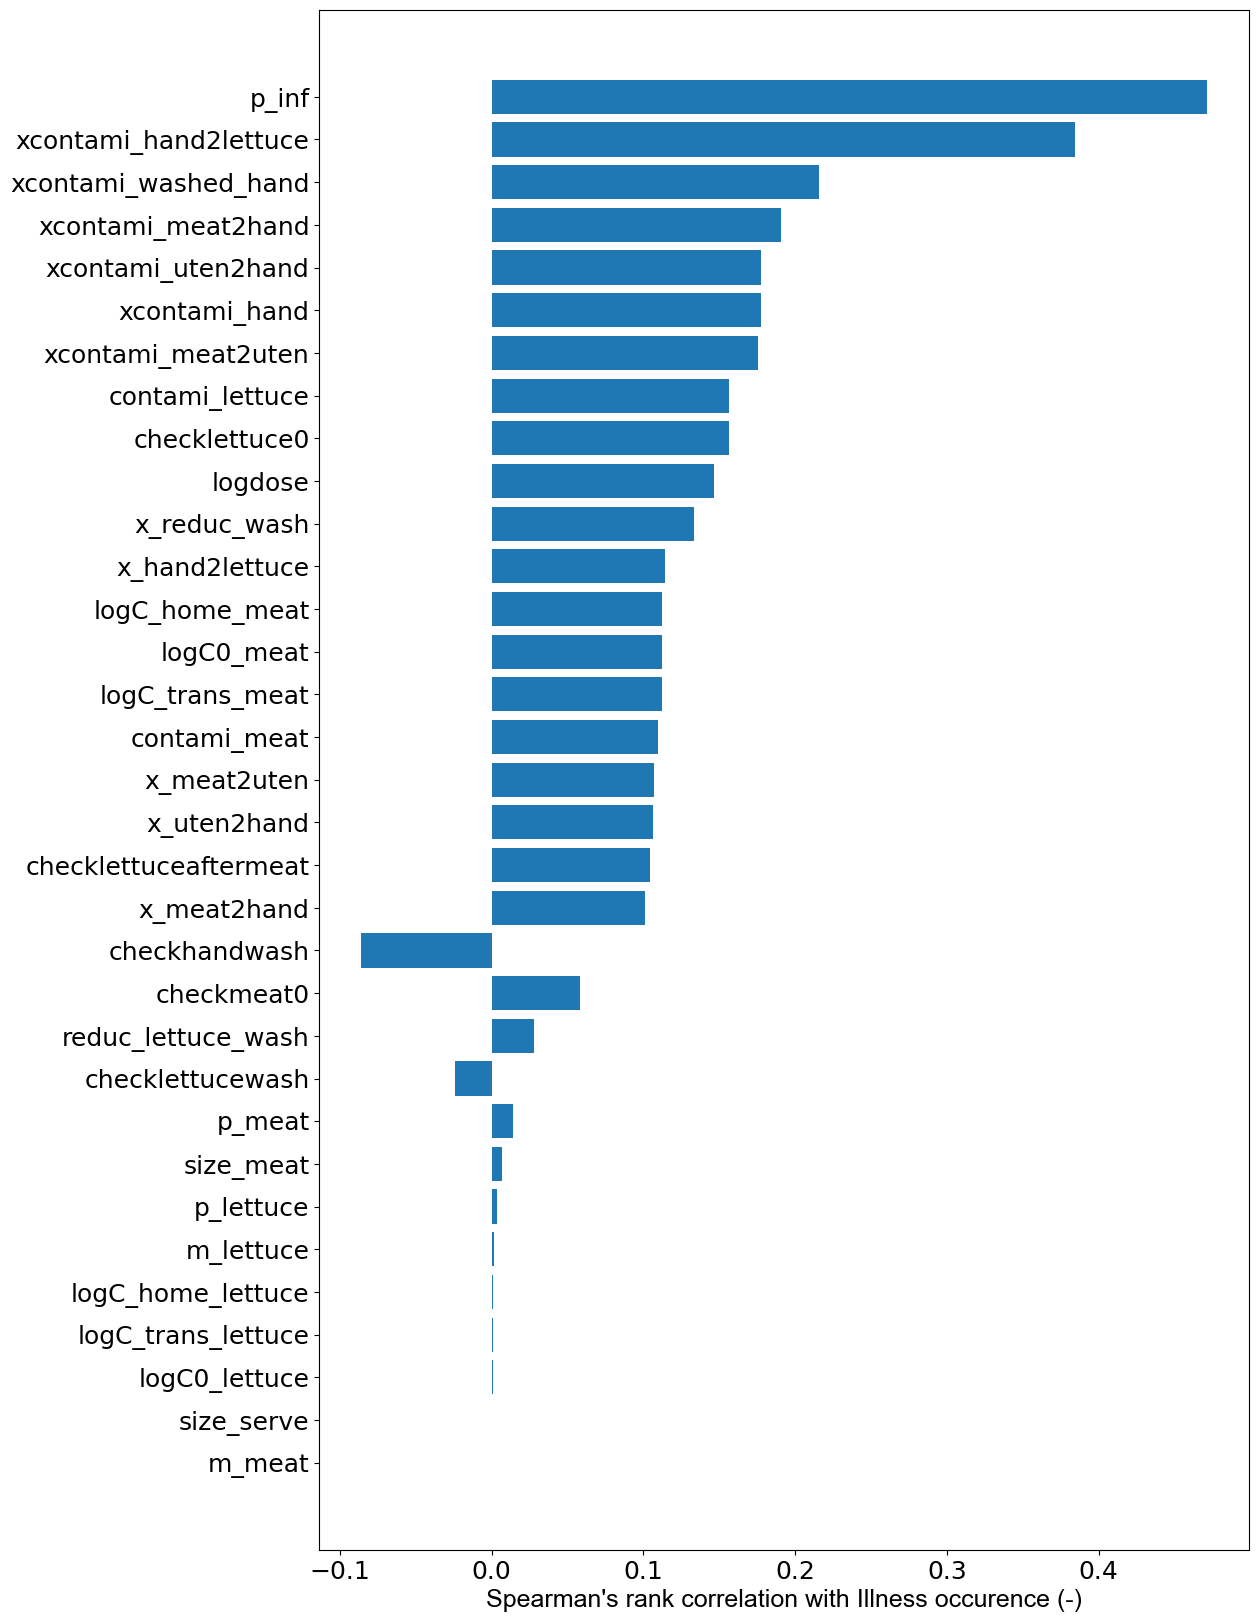

In [25]:
fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_corr.drop('checkInf', axis=0).index, 
        Sensitivity_corr.drop('checkInf', axis=0)["checkInf"])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with Illness occurence (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman.pdf", bbox_inches="tight", dpi=500)
plt.show()

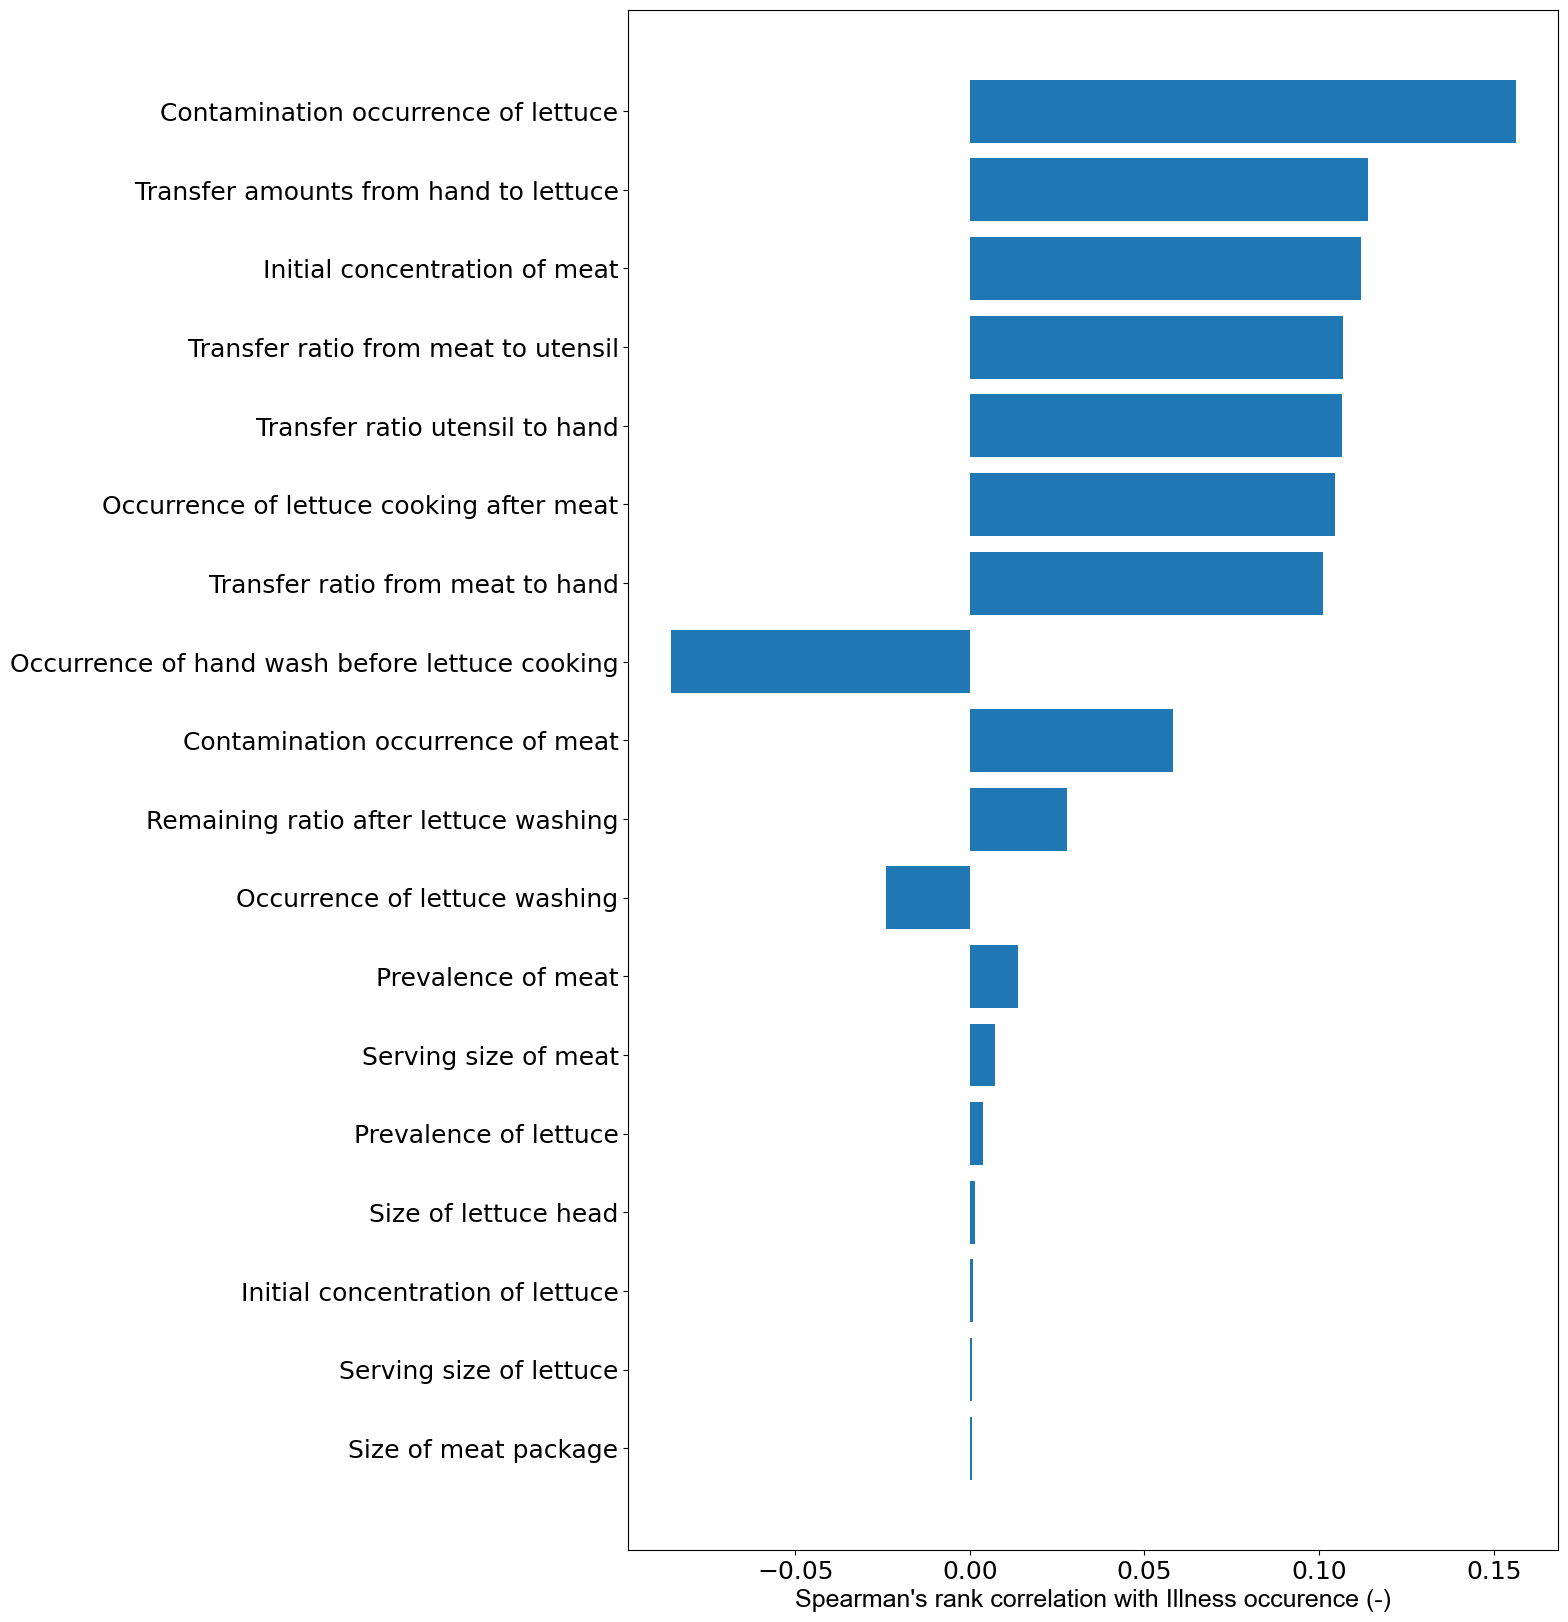

In [26]:
FactorColumns = ['m_lettuce', 'm_meat', 'p_lettuce', 'checklettuce0','logC0_lettuce', 'p_meat', 'checkmeat0', 
                 'logC0_meat', 'size_meat', 'checklettuceaftermeat','x_meat2uten', 'x_meat2hand','x_uten2hand', 
                 'checkhandwash', "checklettucewash", "reduc_lettuce_wash", 'x_hand2lettuce','size_serve']
Sensitivity_factors_corr = Sensitivity_corr.loc[FactorColumns]
Sensitivity_factors_corr = Sensitivity_factors_corr.reindex(Sensitivity_factors_corr["checkInf"].abs().sort_values().index)


Sensitivity_factors_corr = Sensitivity_factors_corr.rename(index={
    'm_lettuce': 'Size of lettuce head',  
    'm_meat': 'Size of meat package',  
    'p_lettuce': 'Prevalence of lettuce',  
    'checklettuce0': 'Contamination occurrence of lettuce', 
    'logC0_lettuce': 'Initial concentration of lettuce', 
    'p_meat': 'Prevalence of meat', 
    'checkmeat0': 'Contamination occurrence of meat', 
    'logC0_meat': 'Initial concentration of meat', 
    'a_growth_lettuce': 'Secondary parameter "a" for lettuce', 
    'b_growth_lettuce': 'Secondary parameter "b" for lettuce', 
    'c_growth_lettuce': 'Secondary parameter "c" for lettuce', 
    'd_growth_lettuce': 'Secondary parameter "d" for lettuce',  
    'h0_growth_lettuce': 'Initial condition parameter "h0" for lettuce',  
    'q0_growth_lettuce': 'Initial condition parameter "q0" for lettuce', 
    'a_growth_meat': 'Secondary parameter "a" for meat',  
    'b_growth_meat': 'Secondary parameter "b" for meat',  
    'c_growth_meat': 'Secondary parameter "c" for meat',  
    'd_growth_meat': 'Secondary parameter "d" for meat', 
    'h0_growth_meat': 'Initial condition parameter "h0" for meat',  
    'q0_growth_meat': 'Initial condition parameter "q0" for meat',  
    'time_trans_lettuce': 'Transportation time of lettuce',  
    'temp_trans_mean_lettuce': 'Mean temperature during transportation of lettuce', 
    'time_home_lettuce': 'Domestic storage time of lettuce', 
    'temp_home_mean_lettuce': 'Mean temperature at home of lettuce', 
    'time_trans_meat': 'Transportation time of meat',  
    'temp_trans_mean_meat': 'Mean temperature during transportation of meat', 
    'time_home_meat': 'Domestic storage time of meat', 
    'temp_home_mean_meat': 'Mean temperature at home of meat', 
    'size_meat': 'Serving size of meat',  
    'checklettuceaftermeat': 'Occurrence of lettuce cooking after meat',  
    'x_meat2uten': 'Transfer ratio from meat to utensil',  
    'x_meat2hand': 'Transfer ratio from meat to hand', 
    'x_uten2hand': 'Transfer ratio utensil to hand',  
    'x_reduc_wash': 'Remaining ratio after hand washing',  
    'checkhandwash': 'Occurrence of hand wash before lettuce cooking',  
    'checklettucewash': 'Occurrence of lettuce washing',  
    'reduc_lettuce_wash': 'Remaining ratio after lettuce washing',  
    'x_hand2lettuce': 'Transfer amounts from hand to lettuce', 
    'size_serve': 'Serving size of lettuce'})

fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_factors_corr.index[0:len(Sensitivity_factors_corr["checkInf"])], 
        Sensitivity_factors_corr["checkInf"][0:len(Sensitivity_factors_corr["checkInf"])])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with Illness occurence (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman factors.pdf", bbox_inches="tight", dpi=500)
plt.show()

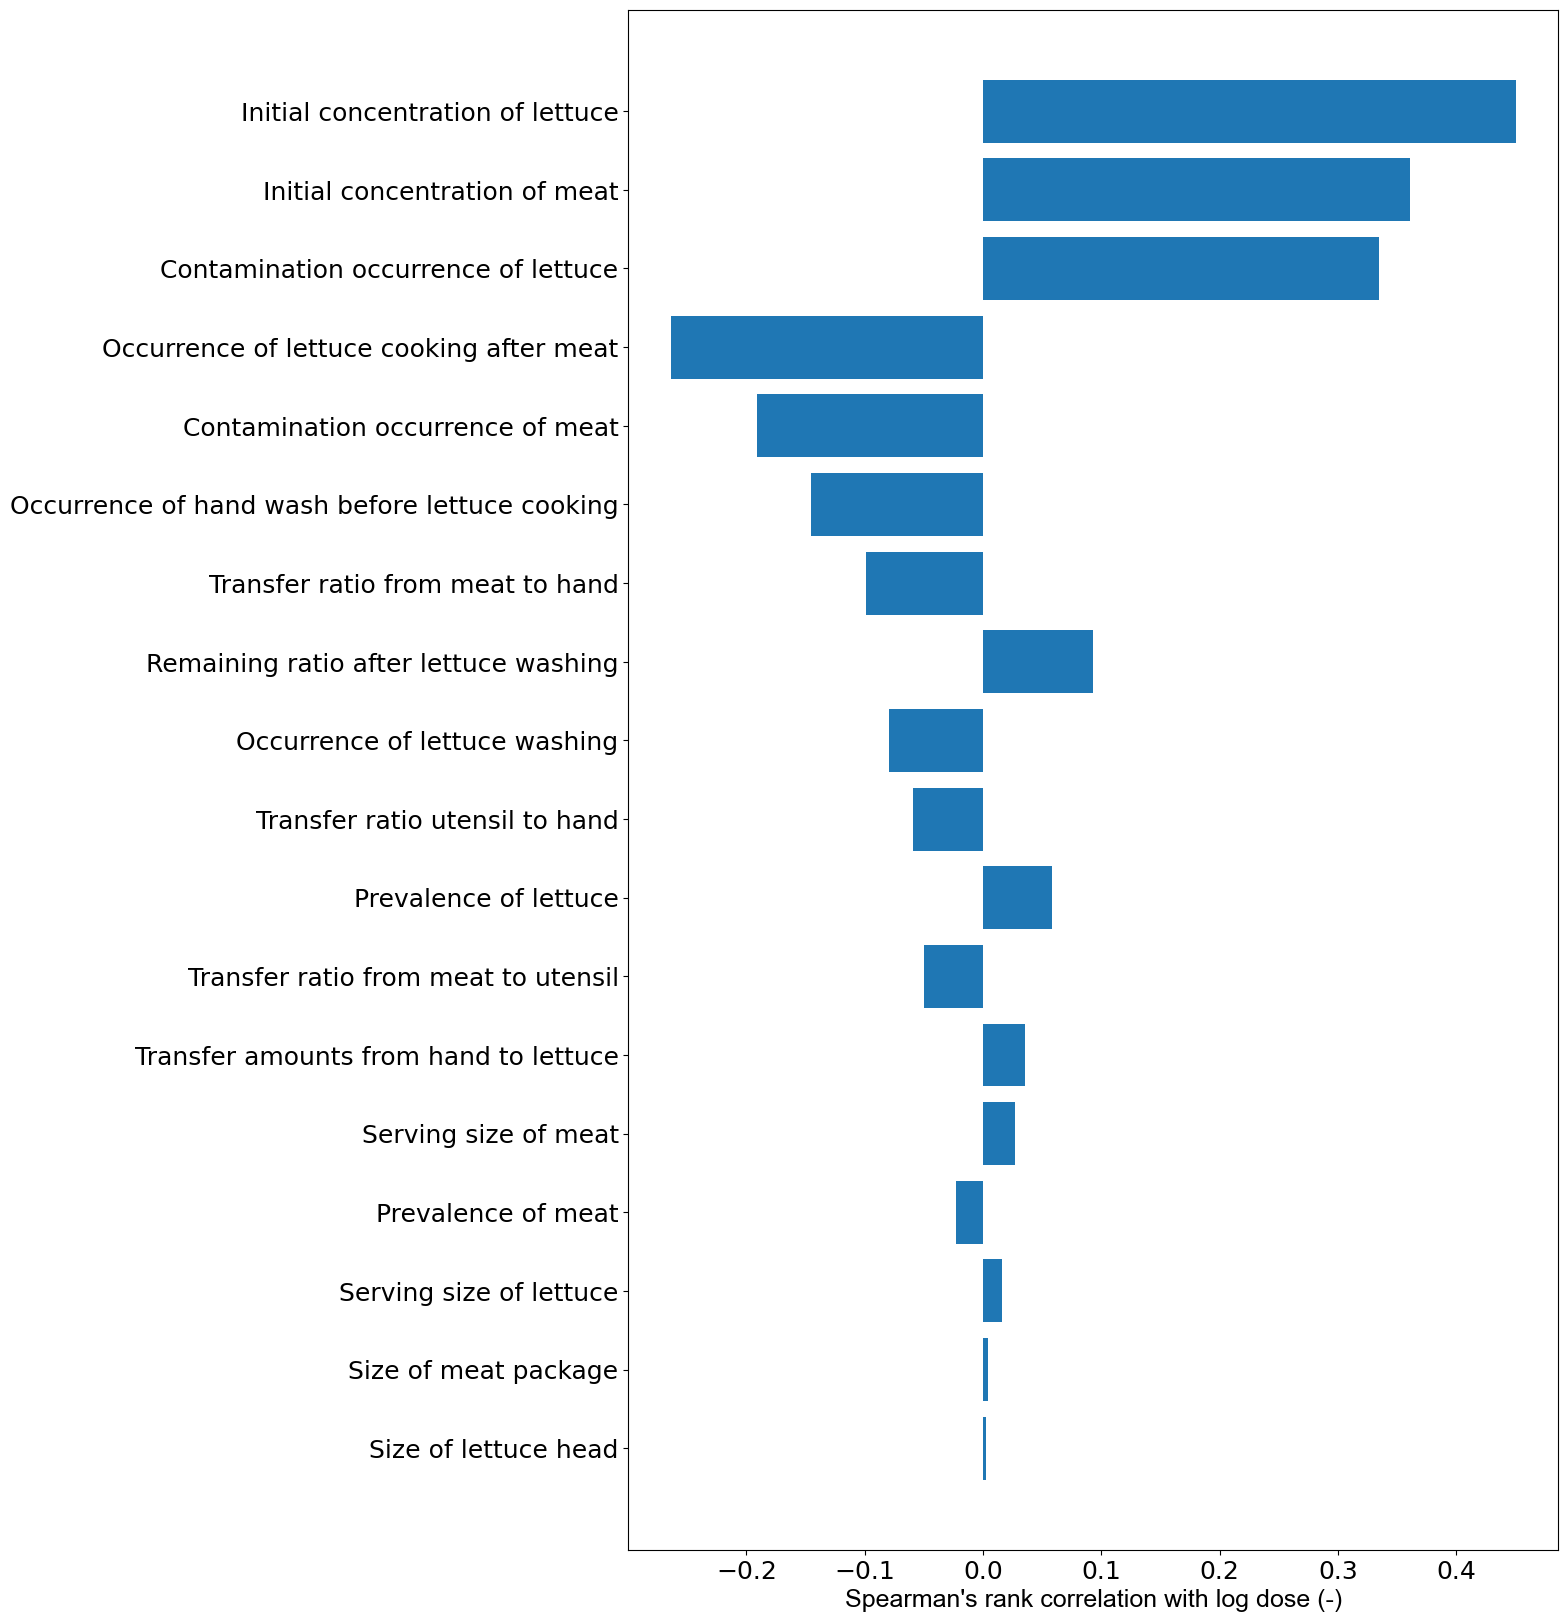

In [27]:
Sensitivity_corr_logdose = pd.read_csv("results/log dose Spearman.csv", index_col=0)
Sensitivity_corr_logdose = Sensitivity_corr_logdose.reindex(Sensitivity_corr_logdose["logdose"].abs().sort_values().index)

FactorColumns = ['m_lettuce', 'm_meat', 'p_lettuce', 'checklettuce0','logC0_lettuce', 'p_meat', 'checkmeat0', 
                 'logC0_meat', 'size_meat', 'checklettuceaftermeat', 'x_meat2uten', 'x_meat2hand','x_uten2hand', 
                 'checkhandwash', 'checklettucewash', 'reduc_lettuce_wash', 'x_hand2lettuce','size_serve']


Sensitivity_factors_corr = Sensitivity_corr_logdose.loc[FactorColumns]
Sensitivity_factors_corr = Sensitivity_factors_corr.reindex(Sensitivity_factors_corr["logdose"].abs().sort_values().index)


Sensitivity_factors_corr = Sensitivity_factors_corr.rename(index={
    'm_lettuce': 'Size of lettuce head',  
    'm_meat': 'Size of meat package',  
    'p_lettuce': 'Prevalence of lettuce',  
    'checklettuce0': 'Contamination occurrence of lettuce', 
    'logC0_lettuce': 'Initial concentration of lettuce', 
    'p_meat': 'Prevalence of meat', 
    'checkmeat0': 'Contamination occurrence of meat', 
    'logC0_meat': 'Initial concentration of meat', 
    'a_growth_lettuce': 'Secondary parameter "a" for lettuce', 
    'b_growth_lettuce': 'Secondary parameter "b" for lettuce', 
    'c_growth_lettuce': 'Secondary parameter "c" for lettuce', 
    'd_growth_lettuce': 'Secondary parameter "d" for lettuce',  
    'h0_growth_lettuce': 'Initial condition parameter "h0" for lettuce',  
    'q0_growth_lettuce': 'Initial condition parameter "q0" for lettuce', 
    'a_growth_meat': 'Secondary parameter "a" for meat',  
    'b_growth_meat': 'Secondary parameter "b" for meat',  
    'c_growth_meat': 'Secondary parameter "c" for meat',  
    'd_growth_meat': 'Secondary parameter "d" for meat', 
    'h0_growth_meat': 'Initial condition parameter "h0" for meat',  
    'q0_growth_meat': 'Initial condition parameter "q0" for meat',  
    'time_trans_lettuce': 'Transportation time of lettuce',  
    'temp_trans_mean_lettuce': 'Mean temperature during transportation of lettuce', 
    'time_home_lettuce': 'Domestic storage time of lettuce', 
    'temp_home_mean_lettuce': 'Mean temperature at home of lettuce', 
    'time_trans_meat': 'Transportation time of meat',  
    'temp_trans_mean_meat': 'Mean temperature during transportation of meat', 
    'time_home_meat': 'Domestic storage time of meat', 
    'temp_home_mean_meat': 'Mean temperature at home of meat', 
    'size_meat': 'Serving size of meat',  
    'checklettuceaftermeat': 'Occurrence of lettuce cooking after meat',  
    'x_meat2uten': 'Transfer ratio from meat to utensil',  
    'x_meat2hand': 'Transfer ratio from meat to hand', 
    'x_uten2hand': 'Transfer ratio utensil to hand',  
    'x_reduc_wash': 'Remaining ratio after hand washing',  
    'checkhandwash': 'Occurrence of hand wash before lettuce cooking',  
    'checklettucewash': 'Occurrence of lettuce washing',  
    'reduc_lettuce_wash': 'Remaining ratio after lettuce washing',  
    'x_hand2lettuce': 'Transfer amounts from hand to lettuce', 
    'size_serve': 'Serving size of lettuce'})

fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_factors_corr.index[0:len(Sensitivity_factors_corr["logdose"])], 
        Sensitivity_factors_corr["logdose"][0:len(Sensitivity_factors_corr["logdose"])])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with log dose (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman log dose.pdf", bbox_inches="tight", dpi=500)
plt.show()

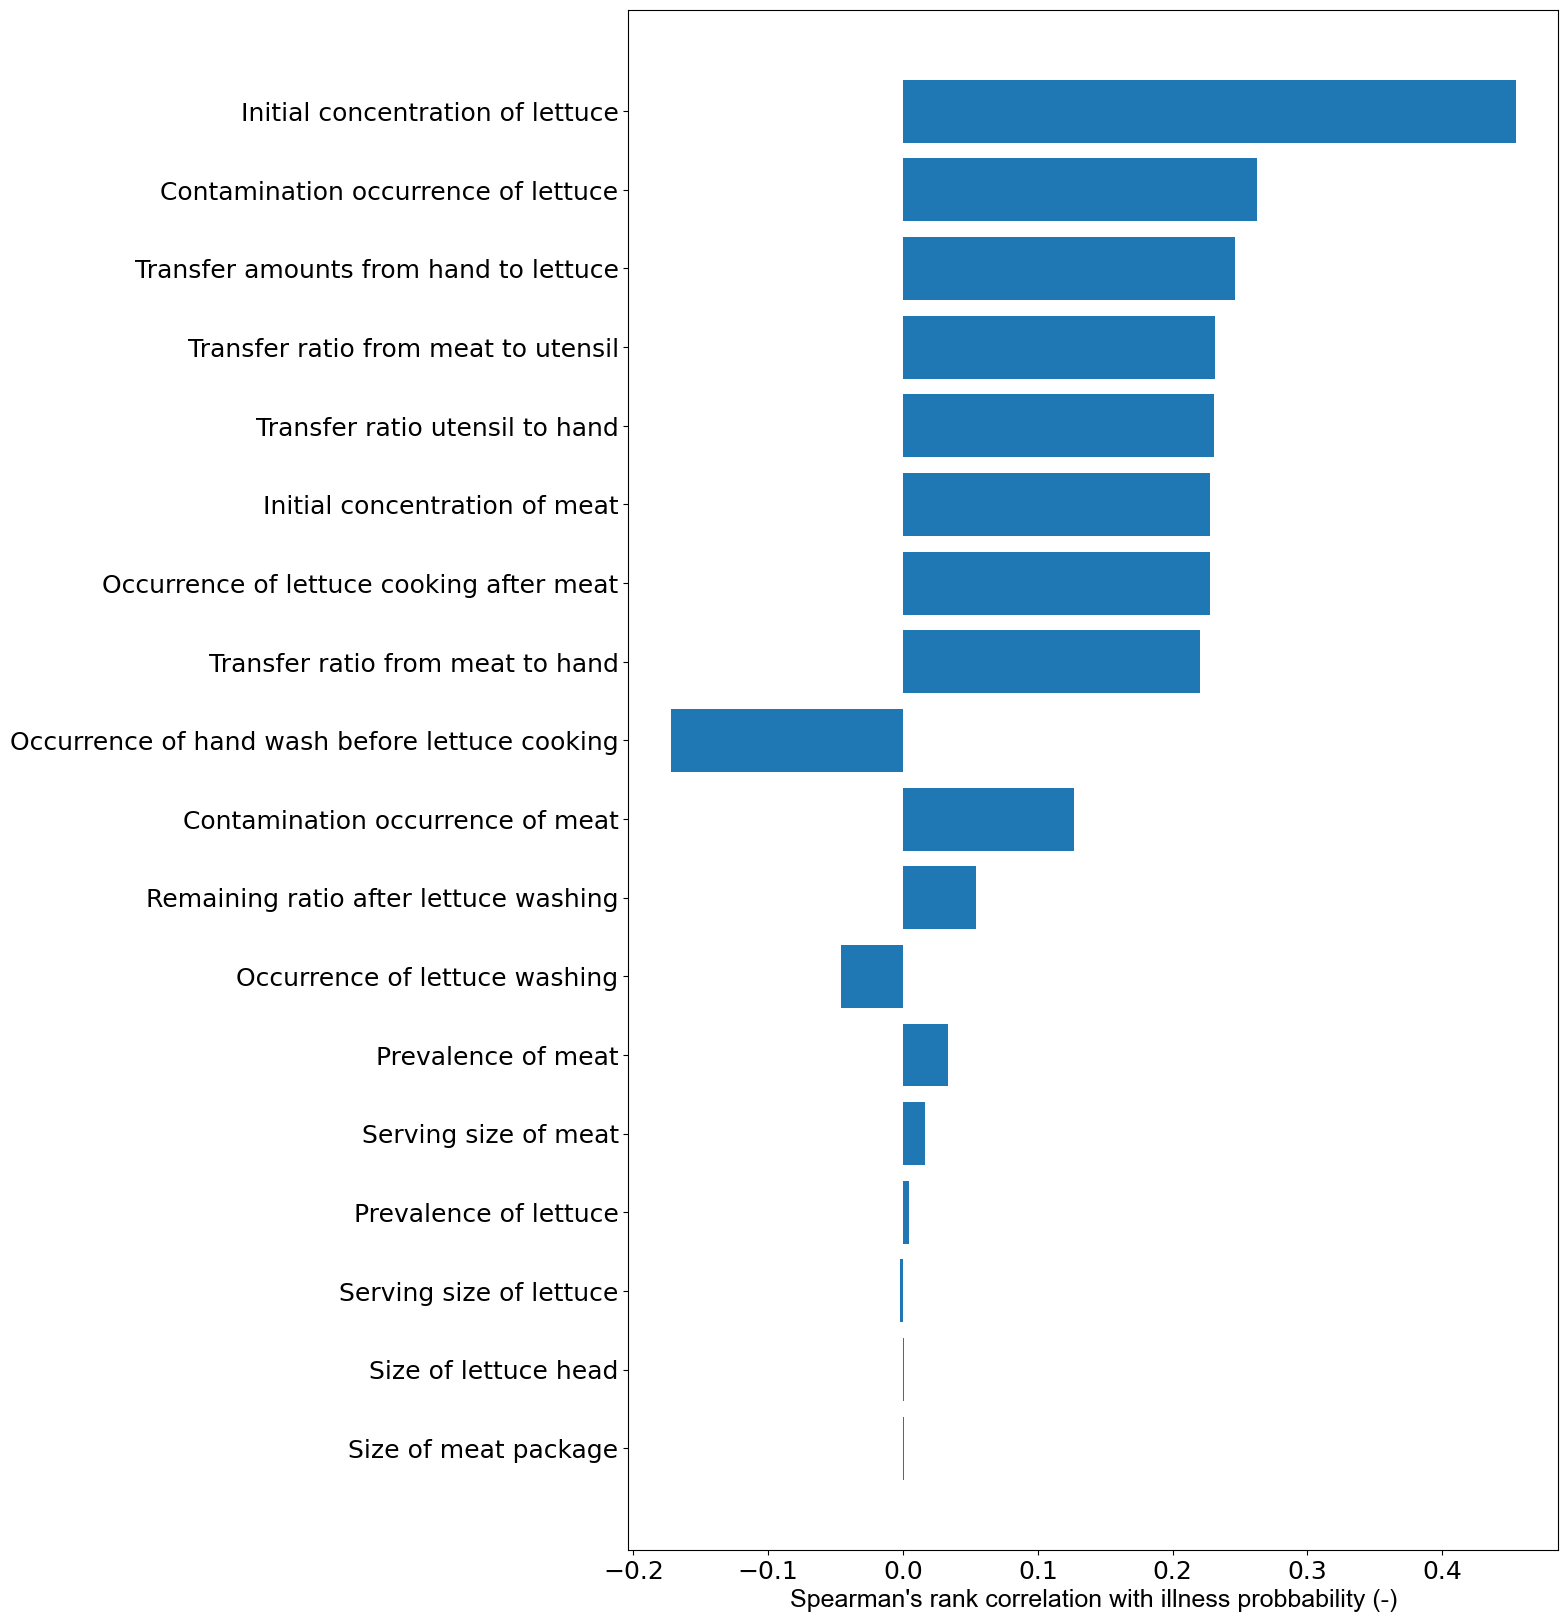

In [28]:
Sensitivity_corr_p_inf = pd.read_csv("results/p_inf Spearman.csv", index_col=0)
Sensitivity_corr_p_inf = Sensitivity_corr_p_inf.reindex(Sensitivity_corr_p_inf["p_inf"].abs().sort_values().index)

FactorColumns = ['m_lettuce', 'm_meat', 'p_lettuce', 'checklettuce0','logC0_lettuce', 'p_meat', 'checkmeat0', 
                 'logC0_meat', 'size_meat', 'checklettuceaftermeat', 'x_meat2uten', 'x_meat2hand','x_uten2hand', 
                 'checkhandwash', 'checklettucewash', 'reduc_lettuce_wash', 'x_hand2lettuce','size_serve']
Sensitivity_factors_corr = Sensitivity_corr_p_inf.loc[FactorColumns]
Sensitivity_factors_corr = Sensitivity_factors_corr.reindex(Sensitivity_factors_corr["p_inf"].abs().sort_values().index)


Sensitivity_factors_corr = Sensitivity_factors_corr.rename(index={
    'm_lettuce': 'Size of lettuce head',  
    'm_meat': 'Size of meat package',  
    'p_lettuce': 'Prevalence of lettuce',  
    'checklettuce0': 'Contamination occurrence of lettuce', 
    'logC0_lettuce': 'Initial concentration of lettuce', 
    'p_meat': 'Prevalence of meat', 
    'checkmeat0': 'Contamination occurrence of meat', 
    'logC0_meat': 'Initial concentration of meat', 
    'a_growth_lettuce': 'Secondary parameter "a" for lettuce', 
    'b_growth_lettuce': 'Secondary parameter "b" for lettuce', 
    'c_growth_lettuce': 'Secondary parameter "c" for lettuce', 
    'd_growth_lettuce': 'Secondary parameter "d" for lettuce',  
    'h0_growth_lettuce': 'Initial condition parameter "h0" for lettuce',  
    'q0_growth_lettuce': 'Initial condition parameter "q0" for lettuce', 
    'a_growth_meat': 'Secondary parameter "a" for meat',  
    'b_growth_meat': 'Secondary parameter "b" for meat',  
    'c_growth_meat': 'Secondary parameter "c" for meat',  
    'd_growth_meat': 'Secondary parameter "d" for meat', 
    'h0_growth_meat': 'Initial condition parameter "h0" for meat',  
    'q0_growth_meat': 'Initial condition parameter "q0" for meat',  
    'time_trans_lettuce': 'Transportation time of lettuce',  
    'temp_trans_mean_lettuce': 'Mean temperature during transportation of lettuce', 
    'time_home_lettuce': 'Domestic storage time of lettuce', 
    'temp_home_mean_lettuce': 'Mean temperature at home of lettuce', 
    'time_trans_meat': 'Transportation time of meat',  
    'temp_trans_mean_meat': 'Mean temperature during transportation of meat', 
    'time_home_meat': 'Domestic storage time of meat', 
    'temp_home_mean_meat': 'Mean temperature at home of meat', 
    'size_meat': 'Serving size of meat',  
    'checklettuceaftermeat': 'Occurrence of lettuce cooking after meat',  
    'x_meat2uten': 'Transfer ratio from meat to utensil',  
    'x_meat2hand': 'Transfer ratio from meat to hand', 
    'x_uten2hand': 'Transfer ratio utensil to hand',  
    'x_reduc_wash': 'Remaining ratio after hand washing',  
    'checkhandwash': 'Occurrence of hand wash before lettuce cooking',  
    'checklettucewash': 'Occurrence of lettuce washing',  
    'reduc_lettuce_wash': 'Remaining ratio after lettuce washing',  
    'x_hand2lettuce': 'Transfer amounts from hand to lettuce', 
    'size_serve': 'Serving size of lettuce'})

fig = plt.figure(figsize =(12,20))
ax = fig.add_subplot(111)
ax.barh(Sensitivity_factors_corr.index[0:len(Sensitivity_factors_corr["p_inf"])], 
        Sensitivity_factors_corr["p_inf"][0:len(Sensitivity_factors_corr["p_inf"])])
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Spearman's rank correlation with illness probbability (-)", size=18, fontname="Arial")
plt.savefig("plot/Spearman p_inf.pdf", bbox_inches="tight", dpi=500)
plt.show()

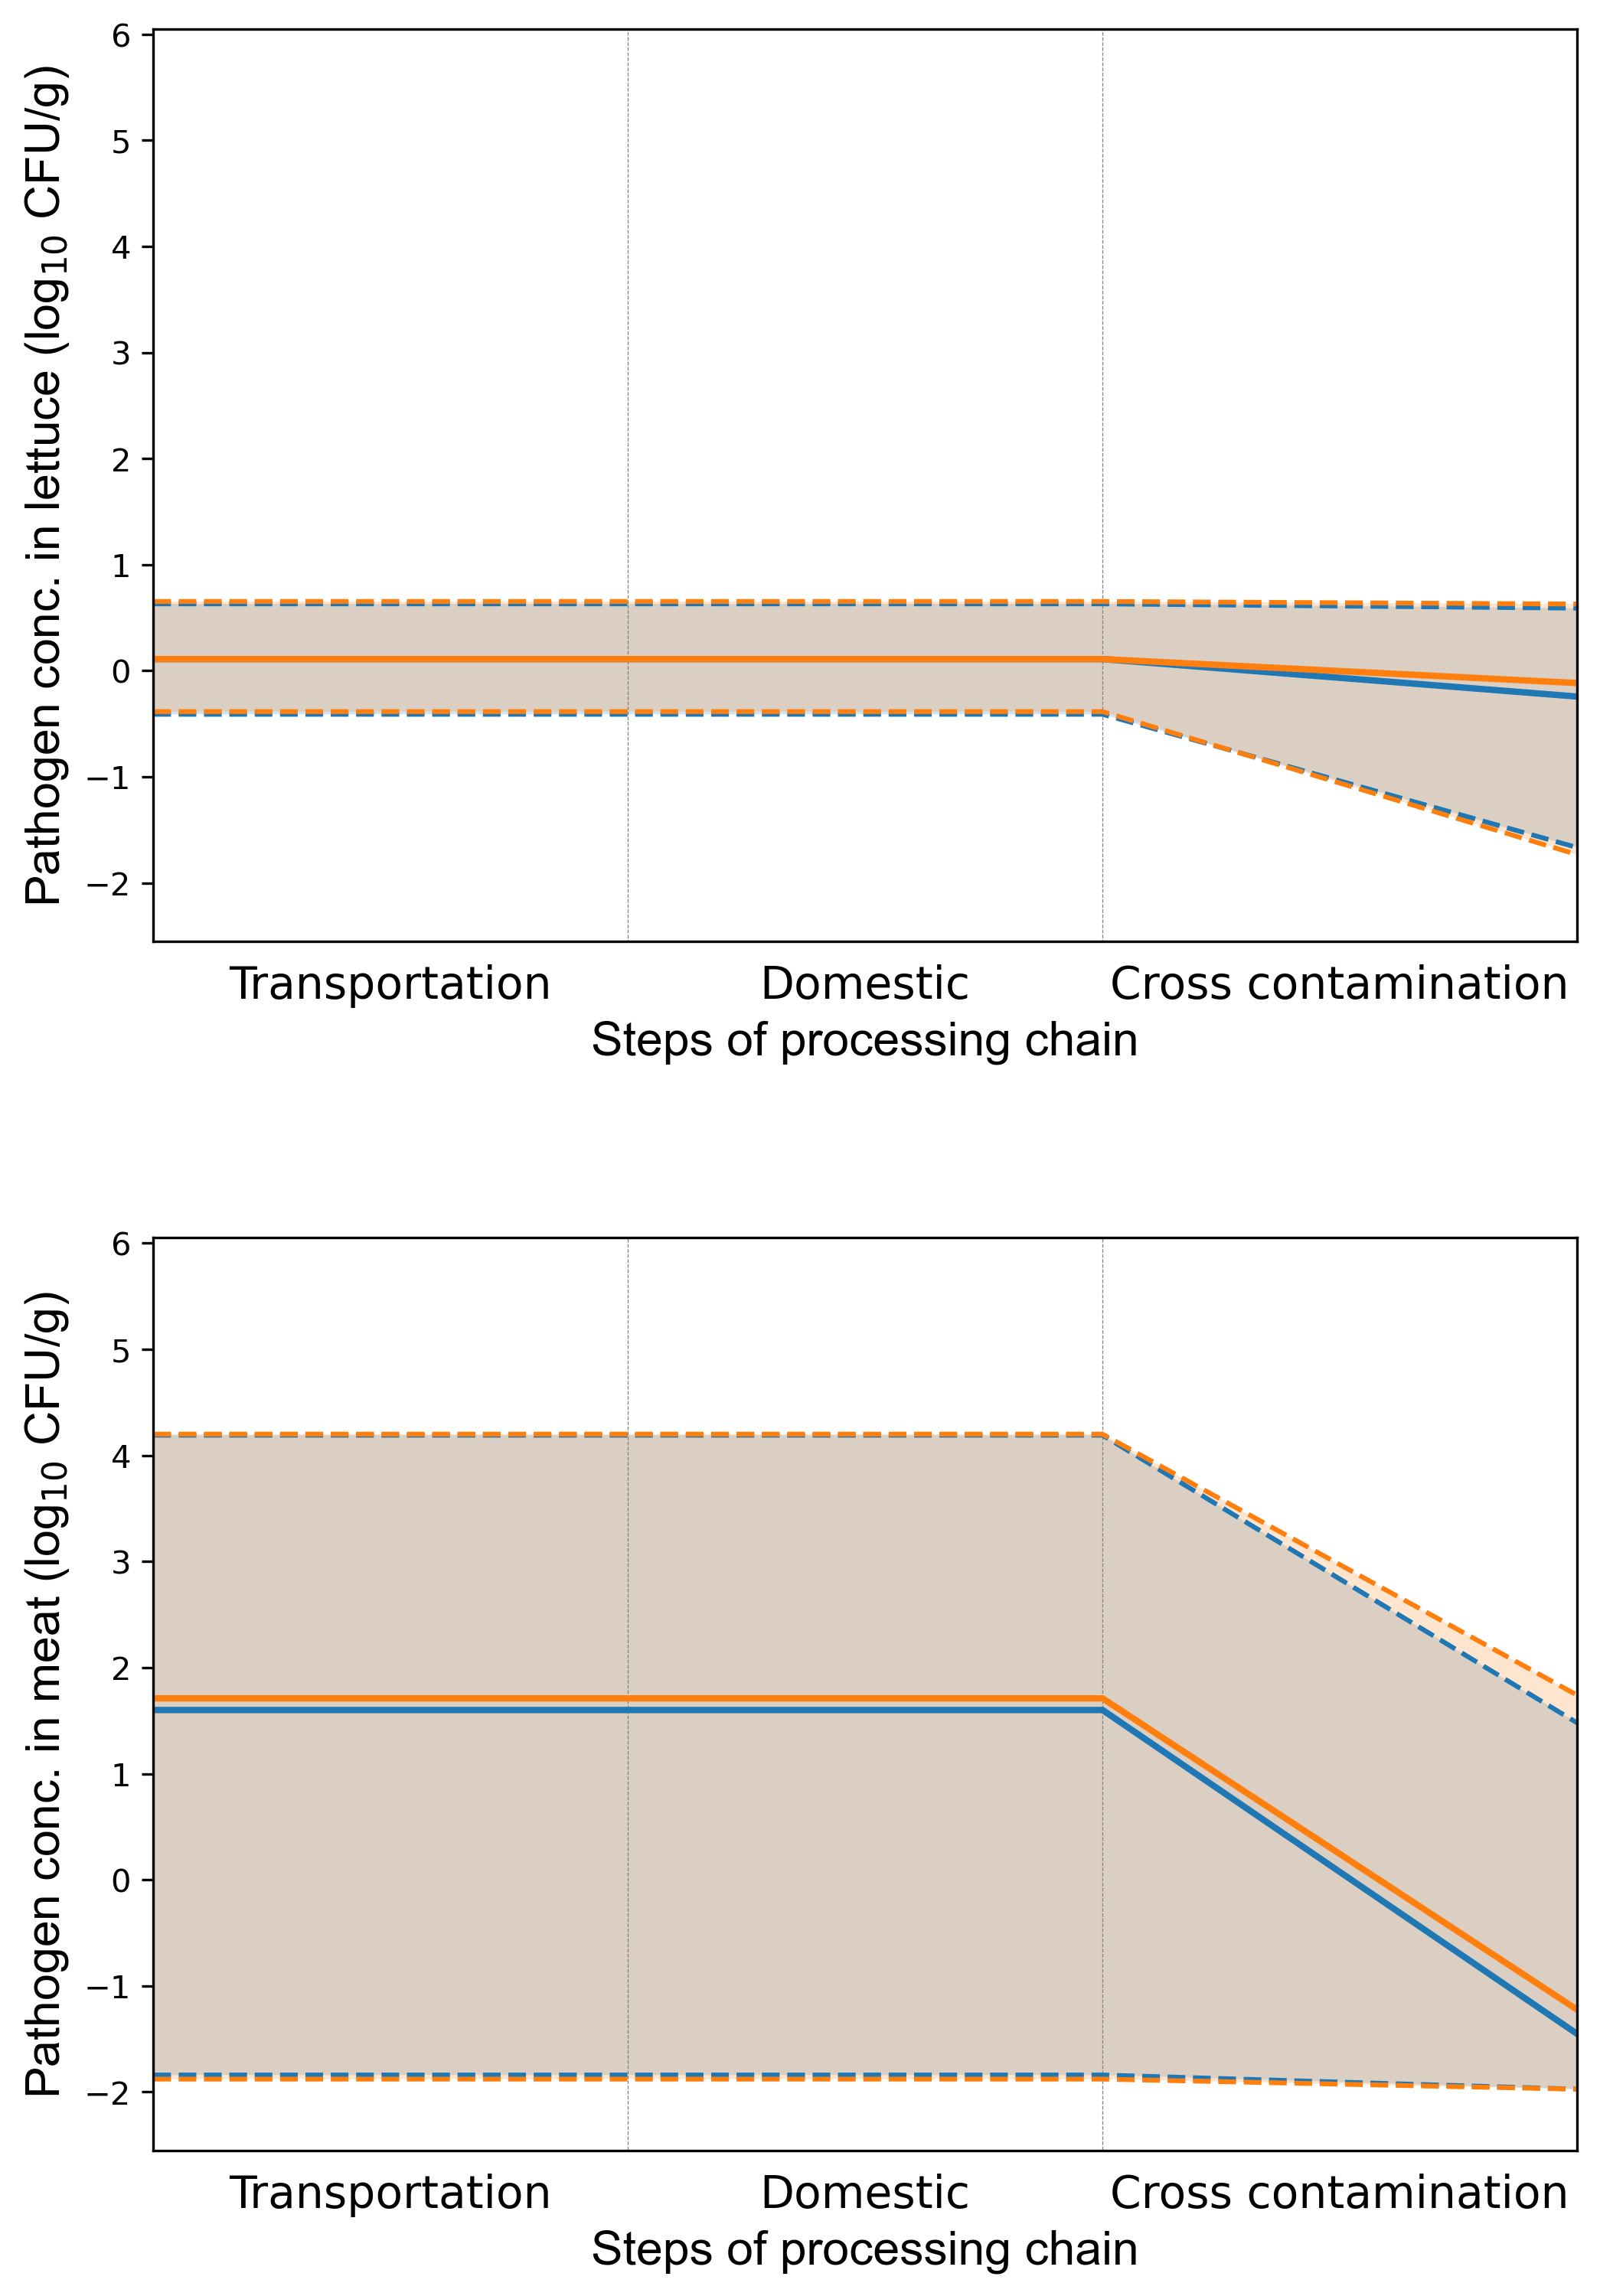

In [31]:
Palette=sns.color_palette(n_colors = 4)
logC0_qtl = np.maximum(np.quantile(Sim_results["logC0_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_qtl = np.maximum(np.quantile(Sim_results["logC_trans_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_home_qtl = np.maximum(np.quantile(Sim_results["logC_home_lettuce"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_qtl = np.maximum(np.quantile(Sim_results["logdose"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)]-np.log10(Sim_results["size_serve"][(Sim_results["checklettuce0"]==1)&(Sim_results["logdose"]!=-np.inf)]),[0.005,  0.5, 0.995]), float(-10**16))



logC0_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC0_lettuce"]
logC_trans_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC_trans_lettuce"]
logC_home_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logC_home_lettuce"]
logC_cross_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["logdose"]-np.log10(Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)]["size_serve"])

logC0_ill_qtl = np.maximum(np.quantile(logC0_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_ill_qtl = np.maximum(np.quantile(logC_trans_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_home_ill_qtl = np.maximum(np.quantile(logC_home_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_ill_qtl = np.maximum(np.quantile(logC_cross_ill,[0.005,  0.5, 0.995]), float(-10**16))



fig, ax = plt.subplots(2, 1, gridspec_kw={'width_ratios': [1], 'height_ratios': [1, 1]},figsize=(8,12), dpi=300)
plt.subplots_adjust(wspace=0, hspace=0.325)
plt.rcParams["font.family"] = "Arial"


ax[0].set_xticks([0.5, 1.5, 2.5])
ax[0].set_xticklabels(["Transportation", "Domestic", "Cross contamination"], size = 14)
ax[0].tick_params(bottom=False)
ax[0].set_ylim([-2.55, 6.05])
ax[0].set_xlim([-0, 3])



ax[0].set_xlabel("Steps of processing chain",size=15,fontname="Arial")
ax[0].set_ylabel("Pathogen conc. in lettuce (log$_{10}$ CFU/g)",size=15,fontname="Arial")


for i in range(5):
    ax[0].axvline(x = i, ymin = -100, ymax = 100, color = "gray", lw = 0.3, linestyle='--')

ax[0].fill_between([0,1,2,3], 
                 [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], 
                 alpha=0.2)
ax[0].fill_between([0,1,2,3], 
                 [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                 alpha=0.2)

#ax[0].fill_between([0,1,2,3], logC_mins, logC_maxs, facecolor=Palette[0], alpha=0.2)

#for i in Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checklettuce0"]==1)].index:
#        ax[0].plot([0,1,2,3], [logC0_ill[i], logC_trans_ill[i], logC_home_ill[i], logC_cross_ill[i]], color=Palette[1], lw = 1.5, alpha=0.8)


ax[0].plot([0,1,2,3], 
         [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], color=Palette[0], linestyle='--')
ax[0].plot([0,1,2,3], 
         [logC0_qtl[1], logC_trans_qtl[1], logC_home_qtl[1], logC_cross_qtl[1]], color=Palette[0], lw=2)
ax[0].plot([0,1,2,3], 
         [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], color=Palette[0], linestyle='--')


ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], color=Palette[1], linestyle='--')
ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[1], logC_trans_ill_qtl[1], logC_home_ill_qtl[1], logC_cross_ill_qtl[1]], color=Palette[1], lw=2)
ax[0].plot([0,1,2,3], 
         [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], color=Palette[1], linestyle='--')



logC0_qtl = np.maximum(np.quantile(Sim_results["logC0_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_qtl = np.maximum(np.quantile(Sim_results["logC_trans_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_home_qtl = np.maximum(np.quantile(Sim_results["logC_home_meat"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)],[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_qtl = np.maximum(np.quantile(Sim_results["logdose"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)]-np.log10(Sim_results["size_serve"][(Sim_results["checkmeat0"]==1)&(Sim_results["logdose"]!=-np.inf)]),[0.005,  0.5, 0.995]), float(-10**16))



logC0_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC0_meat"]
logC_trans_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC_trans_meat"]
logC_home_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logC_home_meat"]
logC_cross_ill = Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["logdose"]-np.log10(Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)]["size_serve"])

logC0_ill_qtl = np.maximum(np.quantile(logC0_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_trans_ill_qtl = np.maximum(np.quantile(logC_trans_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_home_ill_qtl = np.maximum(np.quantile(logC_home_ill,[0.005,  0.5, 0.995]), float(-10**16))
logC_cross_ill_qtl = np.maximum(np.quantile(logC_cross_ill,[0.005,  0.5, 0.995]), float(-10**16))



ax[1].set_xticks([0.5, 1.5, 2.5])
ax[1].set_xticklabels(["Transportation", "Domestic", "Cross contamination"], size = 14)
ax[1].tick_params(bottom=False)
ax[1].set_ylim([-2.55, 6.05])
ax[1].set_xlim([-0, 3])



ax[1].set_xlabel("Steps of processing chain",size=15,fontname="Arial")
ax[1].set_ylabel("Pathogen conc. in meat (log$_{10}$ CFU/g)",size=15,fontname="Arial")


for i in range(5):
    ax[1].axvline(x = i, ymin = -100, ymax = 100, color = "gray", lw = 0.3, linestyle='--')

if logC0_qtl[0] < -3:
    ax[1].fill_between([0,1,2,3], [-3, -3, -3, -3], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], alpha=0.2)

if logC0_qtl[0] > -3:
    ax[1].fill_between([0,1,2,3], [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], facecolor=Palette[0], alpha=0.2)

ax[1].fill_between([0,1,2,3], 
                 [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], facecolor=Palette[1], 
                 alpha=0.2)

#ax[1].fill_between([0,1,2,3], logC_mins, logC_maxs, facecolor=Palette[0], alpha=0.2)


#for i in Sim_results[(Sim_results["checkInf"]==1)&(Sim_results["checkmeat0"]==1)].index:
#        ax[1].plot([0,1,2,3], [logC0_ill[i], logC_trans_ill[i], logC_home_ill[i], logC_cross_ill[i]], color=Palette[1], lw = 1.5, alpha=0.8)

ax[1].plot([0,1,2,3], 
         [logC0_qtl[0], logC_trans_qtl[0], logC_home_qtl[0], logC_cross_qtl[0]], color=Palette[0], linestyle='--')
ax[1].plot([0,1,2,3], 
         [logC0_qtl[1], logC_trans_qtl[1], logC_home_qtl[1], logC_cross_qtl[1]], color=Palette[0], lw=2)
ax[1].plot([0,1,2,3], 
         [logC0_qtl[2], logC_trans_qtl[2], logC_home_qtl[2], logC_cross_qtl[2]], color=Palette[0], linestyle='--')



ax[1].plot([0,1,2,3], 
         [logC0_ill_qtl[0], logC_trans_ill_qtl[0], logC_home_ill_qtl[0], logC_cross_ill_qtl[0]], color=Palette[1], linestyle='--')
ax[1].plot([0,1,2,3], 
         [logC0_ill_qtl[1], logC_trans_ill_qtl[1], logC_home_ill_qtl[1], logC_cross_ill_qtl[1]], color=Palette[1], lw=2)
ax[1].plot([0,1,2,3], 
         [logC0_ill_qtl[2], logC_trans_ill_qtl[2], logC_home_ill_qtl[2], logC_cross_ill_qtl[2]], color=Palette[1], linestyle='--')

plt.savefig("plot/Step and conc.pdf", bbox_inches="tight", dpi=500)
plt.show()


In [29]:
#食中毒件数
np.sum(Sim_results["checkInf"])

3976

In [30]:
Sim_results["logdose"][Sim_results["logdose"]!=0]

0        -inf
1        -inf
2        -inf
3        -inf
4        -inf
         ... 
528395   -inf
528396   -inf
528397   -inf
528398   -inf
528399   -inf
Name: logdose, Length: 522631, dtype: float64

In [31]:
np.sum(Sim_results ["checkmeat0"])

344254

In [32]:
np.sum(Sim_results ["checklettuce0"])

1200

In [33]:
np.sum(Sim_results["checkInf"])

3976

In [34]:
Sim_results[Sim_results["checkInf"]==1]["checkmeat0"]

100       1
193       1
439       1
442       1
611       1
         ..
528017    0
528068    1
528081    1
528298    1
528336    1
Name: checkmeat0, Length: 3976, dtype: int64

In [35]:
Sim_results[Sim_results["checkInf"]==1]["checklettuce0"]

100       0
193       0
439       0
442       0
611       0
         ..
528017    1
528068    0
528081    0
528298    0
528336    0
Name: checklettuce0, Length: 3976, dtype: int64

In [36]:
np.sum(Sim_results ["checkInf"])

3976

(array([1372.,  983.,  568.,  441.,  368.,  129.,   52.,   41.,   18.,
           4.]),
 array([0.   , 0.453, 0.906, 1.359, 1.812, 2.265, 2.718, 3.171, 3.624,
        4.077, 4.53 ]),
 <BarContainer object of 10 artists>)

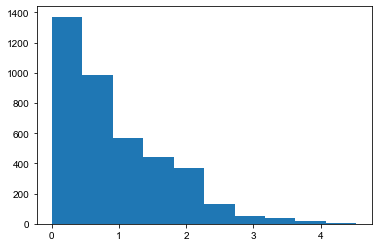

In [37]:
plt.hist(Sim_results["logdose"][Sim_results["checkInf"]==1])

In [38]:
np.sum(Sim_results["checklettuce0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.08777665995975856

In [39]:
np.sum(Sim_results["checkmeat0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.9700704225352113

In [40]:
1-np.sum(Sim_results["checkhandwash"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.6795774647887324

In [41]:
np.sum(Sim_results["checkInf"])

3976

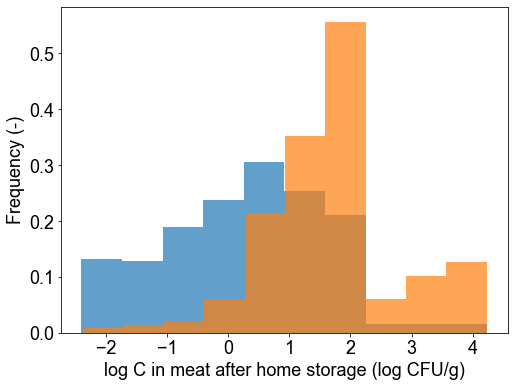

In [42]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC_home_meat"][Sim_results["logC_home_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC_home_meat"][Sim_results_ill["logC_home_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log C in meat after home storage (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/log C in meat after home storage.pdf", bbox_inches="tight", dpi=500)

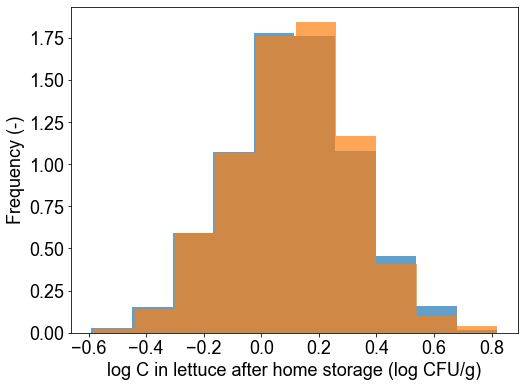

In [43]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC_home_lettuce"][Sim_results["logC_home_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC_home_lettuce"][Sim_results_ill["logC_home_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log C in lettuce after home storage (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/log C in lettuce after home storage.pdf", bbox_inches="tight", dpi=500)

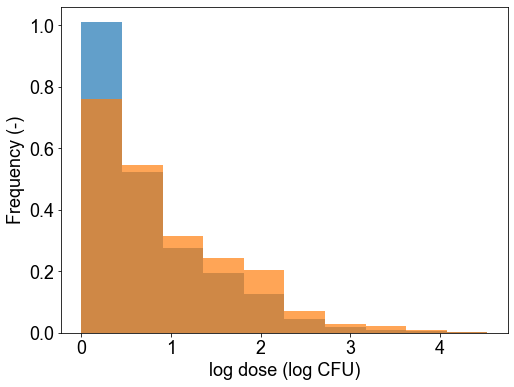

In [44]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logdose"][Sim_results["logdose"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logdose"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/log dose.pdf", bbox_inches="tight", dpi=500)

In [7]:
np.max(Sim_results["logdose"])

4.53

In [8]:
bin_list = [i*0.25 for i in range(21)] 

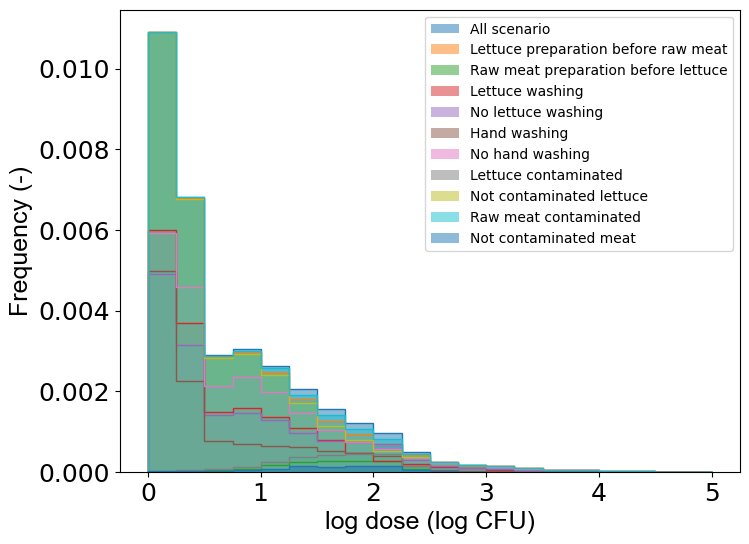

In [9]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuceaftermeat"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce preparation before raw meat")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuceaftermeat"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Raw meat preparation before lettuce")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettucewash"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettucewash"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No lettuce washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkhandwash"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Hand washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkhandwash"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No hand washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuce0"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce contaminated")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuce0"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Not contaminated lettuce")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkmeat0"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Raw meat contaminated")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkmeat0"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Not contaminated meat")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose scenarios.pdf", bbox_inches="tight", dpi=500)

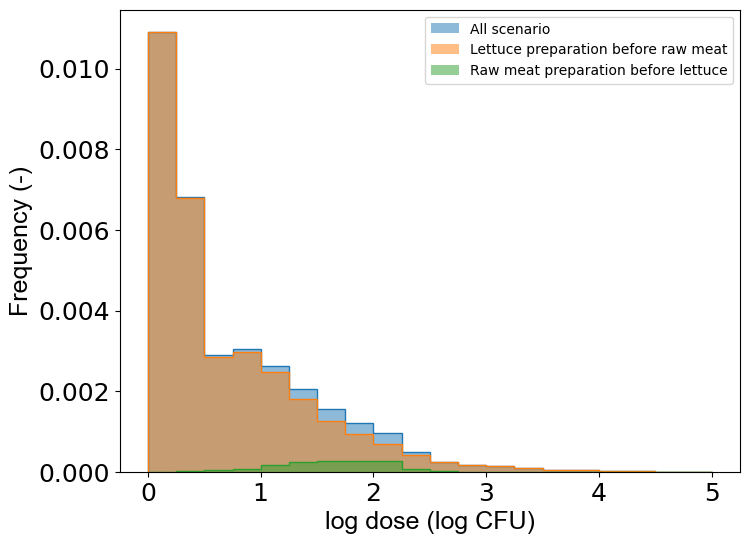

In [10]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuceaftermeat"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce preparation before raw meat")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuceaftermeat"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Raw meat preparation before lettuce")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose preparation sequence.pdf", bbox_inches="tight", dpi=500)

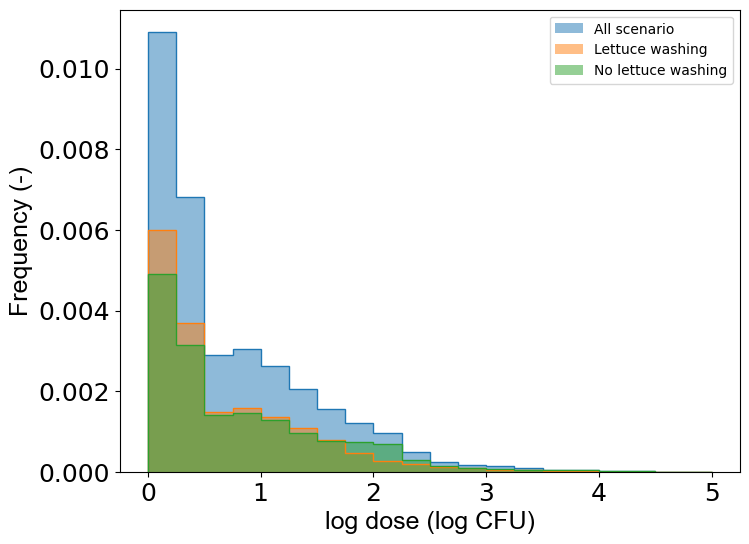

In [11]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettucewash"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettucewash"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No lettuce washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose lettuce wash.pdf", bbox_inches="tight", dpi=500)

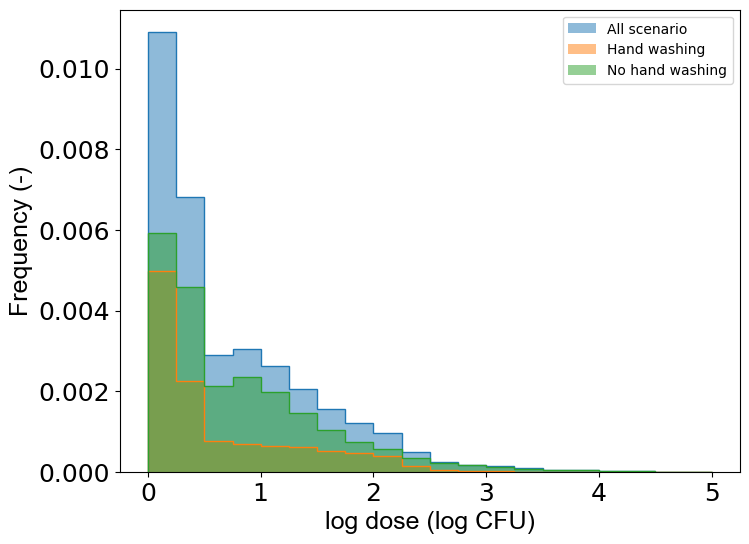

In [12]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkhandwash"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Hand washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkhandwash"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No hand washing")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose hand wash.pdf", bbox_inches="tight", dpi=500)

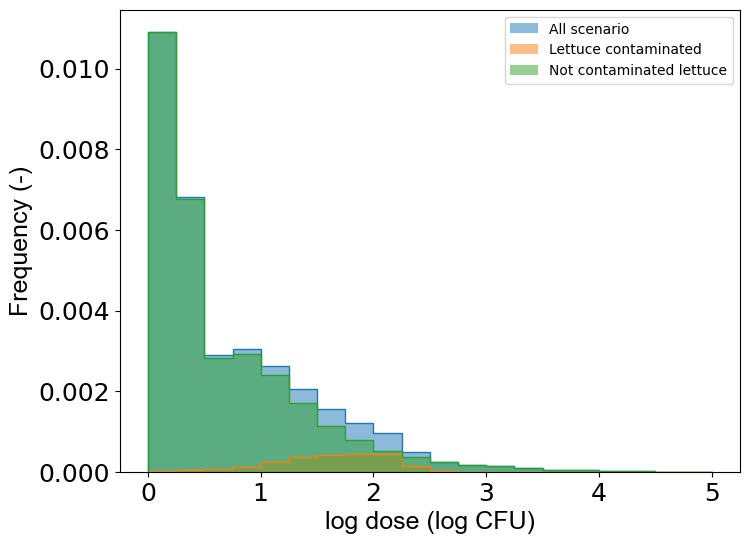

In [13]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuce0"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Lettuce contaminated")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checklettuce0"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Not contaminated lettuce")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose lettuce contamination.pdf", bbox_inches="tight", dpi=500)

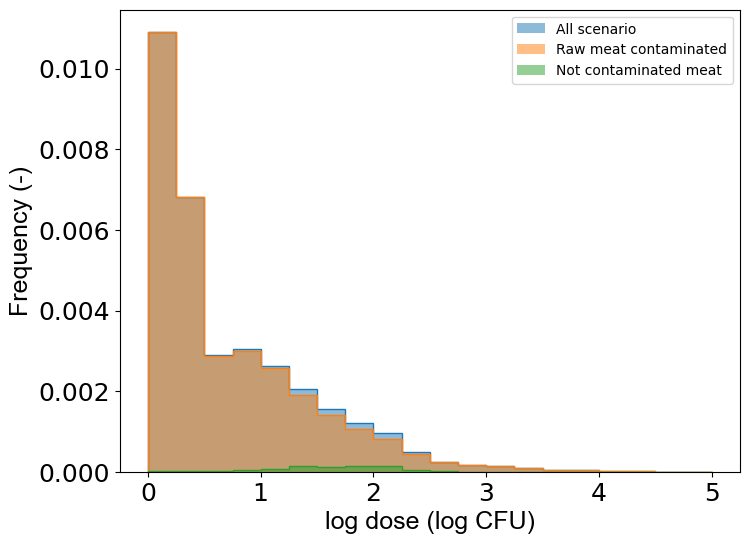

In [14]:
Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkmeat0"]==1]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Raw meat contaminated")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results["logdose"][Sim_results["checkmeat0"]==0]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "Not contaminated meat")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose meat contamination.pdf", bbox_inches="tight", dpi=500)

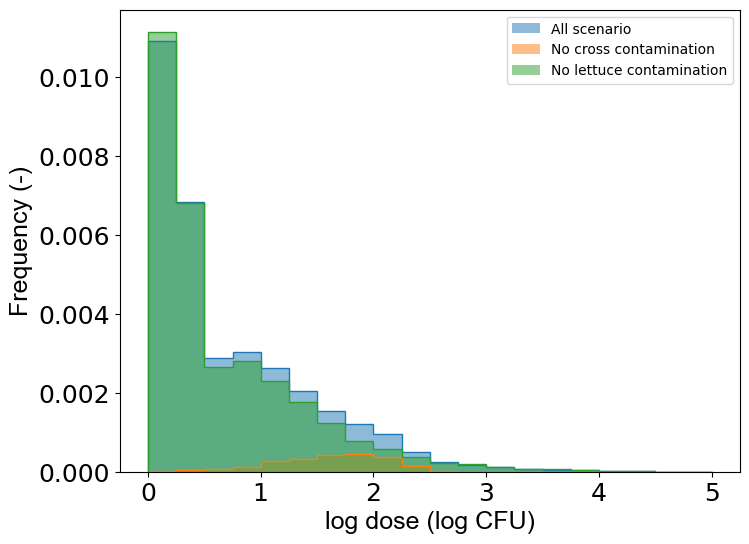

In [16]:
Sim_results_no_cross = pickle.load(open('results/Simulation results of repsim no cross.pkl', 'rb'))
Sim_results_no_lettuce = pickle.load(open('results/Simulation results of repsim no lettuce.pkl', 'rb'))

Palette=sns.color_palette(n_colors = 12)

fig = plt.figure(figsize =(8,6))

data = Sim_results["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results["logdose"])
col = 0
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "All scenario")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results_no_cross["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results_no_cross["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No cross contamination")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

data = Sim_results_no_lettuce["logdose"]

counts, bins = np.histogram(data, bins=bin_list)
counts_normed = counts / len(Sim_results_no_lettuce["logdose"])
col +=1 
plt.hist(bins[:-1], bins=bins, weights=counts_normed, color = Palette[col], alpha =0.5, lw=1, histtype='stepfilled', label = "No lettuce contamination")
plt.hist(bins[:-1], bins=bins, weights=counts_normed, ec = Palette[col], lw=1, histtype='step')

plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("log dose (log CFU)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.legend()
plt.savefig("plot/log dose Table 4.pdf", bbox_inches="tight", dpi=500)

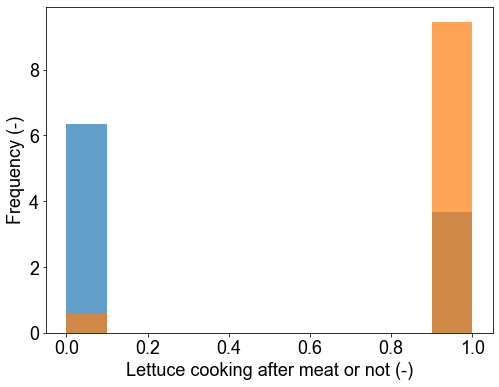

In [45]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["checklettuceaftermeat"][Sim_results["checklettuceaftermeat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["checklettuceaftermeat"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Lettuce cooking after meat or not (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Lettuce cooking after meat or not.pdf", bbox_inches="tight", dpi=500)

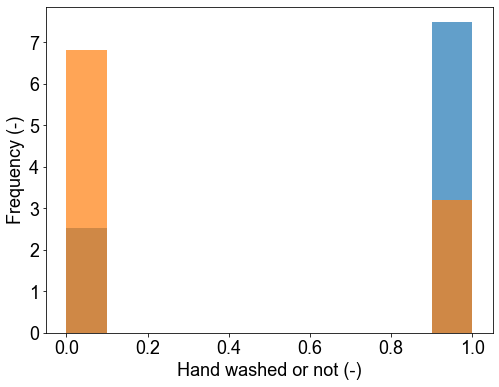

In [46]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["checkhandwash"][Sim_results["checkhandwash"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["checkhandwash"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Hand washed or not (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Hand washed or not.pdf", bbox_inches="tight", dpi=500)

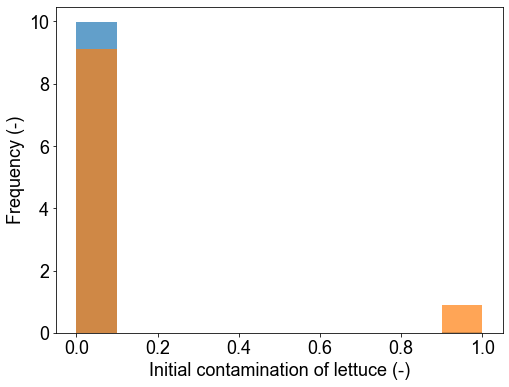

In [47]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["checklettuce0"][Sim_results["checklettuce0"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["checklettuce0"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Initial contamination of lettuce (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Initial contamination of lettuce.pdf", bbox_inches="tight", dpi=500)

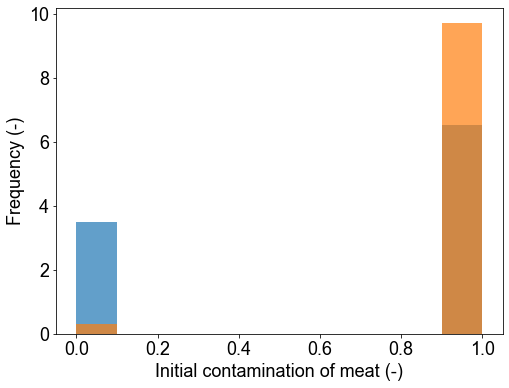

In [48]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["checkmeat0"][Sim_results["checkmeat0"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["checkmeat0"],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Initial contamination of meat (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Initial contamination of meat.pdf", bbox_inches="tight", dpi=500)

(array([9.2190869 , 4.3138876 , 3.89056218, 3.45379786, 2.60714702,
        1.90160466, 0.69210346, 0.3292531 , 0.25533914, 0.05375561]),
 array([0.1621 , 0.19953, 0.23696, 0.27439, 0.31182, 0.34925, 0.38668,
        0.42411, 0.46154, 0.49897, 0.5364 ]),
 <BarContainer object of 10 artists>)

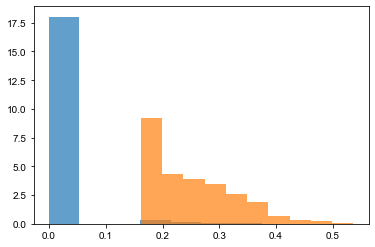

In [49]:
plt.hist(Sim_results["p_inf"][Sim_results["p_inf"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["p_inf"],density=True, alpha =0.7)

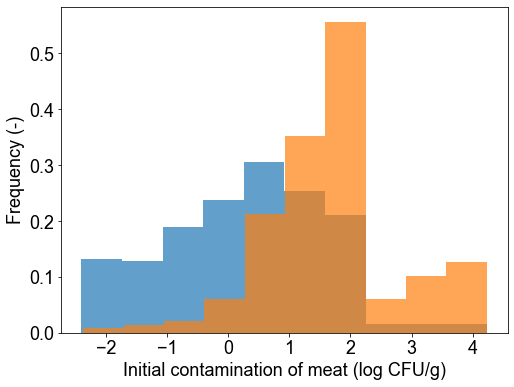

In [50]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC0_meat"][Sim_results["logC0_meat"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC0_meat"][Sim_results["logC0_meat"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Initial contamination of meat (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Initial contamination of meat.pdf", bbox_inches="tight", dpi=500)

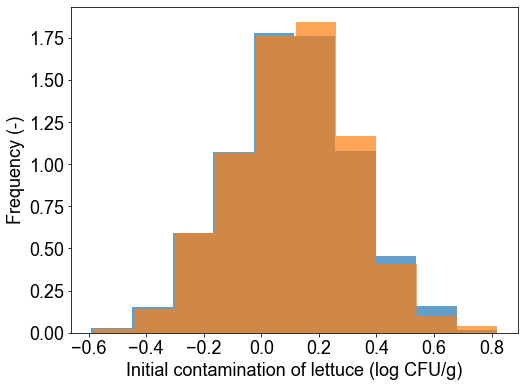

In [51]:
fig = plt.figure(figsize =(8,6))
plt.hist(Sim_results["logC0_lettuce"][Sim_results["logC0_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.hist(Sim_results_ill["logC0_lettuce"][Sim_results["logC0_lettuce"]!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Initial contamination of lettuce (log CFU/g)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Initial contamination of lettuce.pdf", bbox_inches="tight", dpi=500)

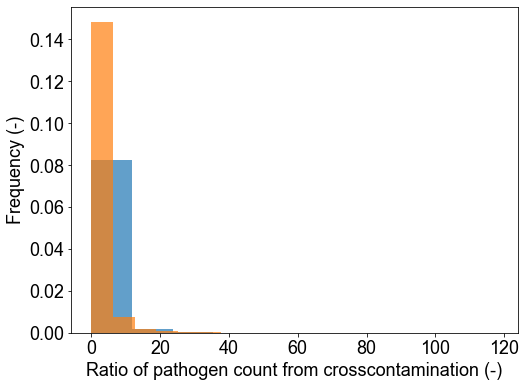

In [52]:
ratio_x = Sim_results["xcontami_hand2lettuce"]/10**(Sim_results["logdose"])
ratio_x_ill = Sim_results_ill["xcontami_hand2lettuce"]/10**(Sim_results_ill["logdose"])

fig = plt.figure(figsize =(8,6))
plt.hist(ratio_x[(ratio_x!=-np.inf)&(ratio_x!=np.inf)],density=True, alpha =0.7)
plt.hist(ratio_x_ill[ratio_x_ill!=-np.inf],density=True, alpha =0.7)
plt.xticks(size=18)
plt.yticks(size=18)
plt.xlabel("Ratio of pathogen count from crosscontamination (-)", size=18, fontname="Arial")
plt.ylabel("Frequency (-)", size=18, fontname="Arial")
plt.savefig("plot/Ratio of pathogen count from cross-contamination.pdf", bbox_inches="tight", dpi=500)

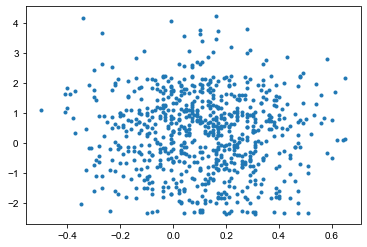

In [53]:
plt.plot(Sim_results["logC0_lettuce"],Sim_results["logC0_meat"], marker='.', linewidth=0)

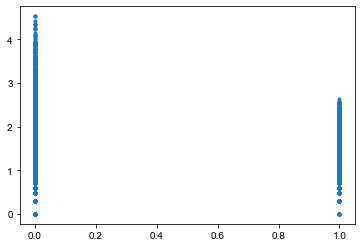

In [54]:
plt.plot(Sim_results["checklettuce0"],Sim_results["logdose"], marker='.', linewidth=0)

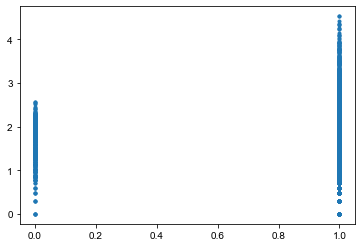

In [55]:
plt.plot(Sim_results["checkmeat0"],Sim_results["logdose"], marker='.', linewidth=0)

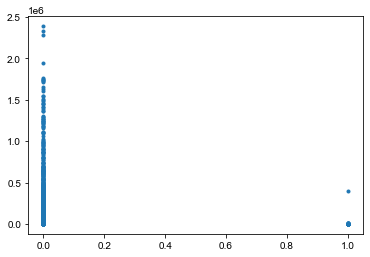

In [56]:
plt.plot(Sim_results["checklettuce0"],Sim_results["xcontami_washed_hand"], marker='.', linewidth=0)

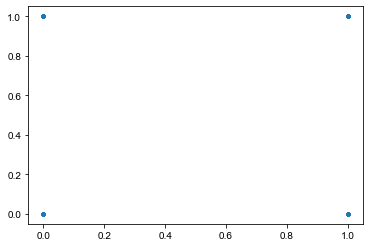

In [57]:
plt.plot(Sim_results["checklettuce0"],Sim_results["checkmeat0"], marker='.', linewidth=0)

In [58]:
#レタス汚染の数
np.sum(Sim_results["checklettuce0"])

1200

In [59]:
#肉汚染の数
np.sum(Sim_results["checkmeat0"])

344254

In [60]:
#レタス汚染かつ肉汚染の数
np.sum(Sim_results["checkmeat0"][Sim_results["checklettuce0"]==1])

790

In [61]:
#病気の中のレタス有病率
np.sum(Sim_results["checklettuce0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.08777665995975856

In [62]:
#感染の中の肉有病率
np.sum(Sim_results["checkmeat0"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.9700704225352113

In [63]:
#感染の中の生肉を先に調理している確率
np.sum(Sim_results["checklettuceaftermeat"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.9439134808853119

In [64]:
#感染の中のレタスを洗っている割合
np.sum(Sim_results["checklettucewash"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.5022635814889336

In [65]:
#感染の中の手洗いしていない率
1-np.sum(Sim_results["checkhandwash"][Sim_results["checkInf"]==1])/np.sum(Sim_results["checkInf"][Sim_results["checkInf"]==1])

0.6795774647887324

(0.0, 1.0)

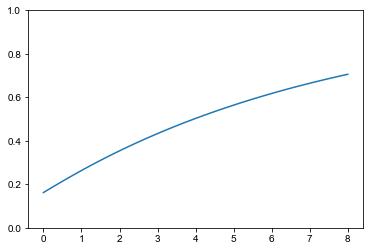

In [66]:
logdds = np.linspace(0, 8, int(8*10+1), endpoint = True)
probss = np.linspace(0, 8, int(8*10+1), endpoint = True)
for i in range (len(logdds)):
    probss[i] = DRmodel_Appro_Beta_Pois(10**logdds[i])
plt.plot(logdds, probss)
plt.ylim([0,1])

In [67]:
#生肉を先に調理しているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettuceaftermeat"]==1])

0.019683876241722766

In [68]:
#レタスを先に調理しているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettuceaftermeat"]==0])

0.0007256164955836721

In [69]:
#レタスを洗っているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettucewash"]==1])

0.0060664901440724735

In [70]:
#レタスを洗っていないシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettucewash"]==0])

0.010424892221860237

In [71]:
#手を洗っているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checkhandwash"]==1])

0.003356429589246389

In [72]:
#手を洗っていないシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checkhandwash"]==0])

0.02041705964875503

In [73]:
#レタスが汚染しているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettuce0"]==1])

0.3185873333333336

In [74]:
#レタスが汚染していないシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checklettuce0"]==0])

0.006952510242792438

In [75]:
#生肉が汚染しているシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checkmeat0"]==1])

0.011378547816438385

In [76]:
#生肉が汚染していないシナリオのリスク平均
np.mean(Sim_results['p_inf'][Sim_results["checkmeat0"]==0])

0.0007089896060734416

In [20]:
#レタスを先に調理して、手を洗っていて、レタスを洗っているシナリオのリスク平均
np.mean(Sim_results['p_inf'][(Sim_results["checklettuceaftermeat"]==0)&(Sim_results["checkhandwash"]==1)&(Sim_results["checklettucewash"]==1)])

0.0006957602973641011

In [21]:
#手を洗っていて、レタスを洗っているシナリオのリスク平均
np.mean(Sim_results['p_inf'][(Sim_results["checkhandwash"]==1)&(Sim_results["checklettucewash"]==1)])

0.002551390267925145

In [65]:
#pg = sns.pairplot(Sim_results)
#pg.savefig('seaborn_pairplot_default.png')

In [66]:
Sensitivity_corr_all = Sim_results.corr(method="spearman")

In [67]:
Sensitivity_corr_all

,checkInf,m_lettuce,m_meat,p_lettuce,checklettuce0,logC0_lettuce,p_meat,checkmeat0,logC0_meat,logC_trans_lettuce,...,xcontami_meat2hand,xcontami_hand,xcontami_washed_hand,xcontami_hand2lettuce,contami_lettuce,size_serve,checklettucewash,reduc_lettuce_wash,logdose,p_inf
checkInf,1.000000,0.001533,0.000544,0.003707,0.156409,0.000988,0.013921,0.058214,0.112088,0.000988,...,0.190691,0.177468,0.215868,0.384203,0.156409,0.000551,-0.023875,0.027734,0.146566,0.471440
m_lettuce,0.001533,1.000000,-0.001969,-0.001619,-0.000019,0.010060,0.001494,0.002062,-0.000479,0.010060,...,0.001003,0.000356,0.000941,0.001624,-0.000019,-0.013000,-0.001537,0.001512,0.002766,0.001000
m_meat,0.000544,-0.001969,1.000000,-0.000330,0.000108,0.004834,0.000010,0.000498,-0.004606,0.004834,...,0.000757,0.000269,0.000963,0.001689,0.000108,0.000642,-0.001875,0.001394,0.003927,0.000676
p_lettuce,0.003707,-0.001619,-0.000330,1.000000,0.022532,-0.041362,0.000161,0.000485,0.000277,-0.041362,...,-0.001953,-0.002039,-0.001463,0.000518,0.022530,0.001566,0.002603,-0.001867,0.058243,0.004376
checklettuce0,0.156409,-0.000019,0.000108,0.022532,1.000000,NaN,0.001566,0.000684,0.000788,NaN,...,-0.001478,-0.001065,-0.000850,-0.000625,0.999999,0.000833,-0.000346,0.000229,0.335031,0.262268
logC0_lettuce,0.000988,0.010060,0.004834,-0.041362,NaN,1.000000,-0.040017,0.035490,-0.041056,1.000000,...,0.044993,0.042068,0.037363,0.024753,0.975275,-0.027671,-0.017267,0.029854,0.450729,0.454714
p_meat,0.013921,0.001494,0.000010,0.000161,0.001566,-0.040017,1.000000,0.253405,0.001851,-0.040017,...,0.085088,0.096391,0.078677,0.039730,0.001564,-0.000575,0.000785,-0.000539,-0.022867,0.033011
checkmeat0,0.058214,0.002062,0.000498,0.000485,0.000684,0.035490,0.253405,1.000000,NaN,0.035490,...,0.326684,0.373872,0.299096,0.152755,0.000686,0.000896,0.002056,-0.001222,-0.191423,0.126507
logC0_meat,0.112088,-0.000479,-0.004606,0.000277,0.000788,-0.041056,0.001851,NaN,1.000000,-0.041056,...,0.320160,0.206840,0.282284,0.256031,0.000785,0.001913,-0.000143,-0.001375,0.361070,0.227791
logC_trans_lettuce,0.000988,0.010060,0.004834,-0.041362,NaN,1.000000,-0.040017,0.035490,-0.041056,1.000000,...,0.044993,0.042068,0.037363,0.024753,0.975275,-0.027671,-0.017267,0.029854,0.450729,0.454714
